# Data Driven Solutions and Discoveries in Mechanics Using Physics-Informed Neural Networks

### Machine Learning Mini Project

**Reference Paper:**  
Qi Zhang, Yilin Chen and Ziyi Yang,  
*Data Driven Solutions and Discoveries in Mechanics Using Physics Informed Neural Network*

**Team Members:**  
1. Prakruti Prasanna Bhat (PES1UG24CS330)  
2. Pushkar S Kulkarni (PES1UG24CS350)

## Project Objective

This mini-project reproduces the three Physics-Informed Neural Network
(PINN) experiments presented in the reference paper.

The experiments considered are:

1. One-dimensional consolidation problem
2. Two-dimensional steady-state heat conduction problem
3. Inverse parameter identification for a structural dynamic system

A Physics-Informed Neural Network differs from a conventional neural
network because its loss function incorporates the governing physical
equations in addition to boundary conditions and available observations.

For the forward problems, the neural network approximates the unknown
solution of the differential equation.

For the inverse problem, the PINN simultaneously approximates the
system response and identifies unknown physical parameters.

## Implementation Notes

The reference paper provides the governing equations, network
architectures, training-point counts, loss weights, optimizers and
several training hyperparameters.

However, some lower-level implementation details are not reported.

Throughout this notebook:

- Parameters explicitly reported in the paper are marked as FROM PAPER.
- Decisions not specified by the authors are marked as
  OUR IMPLEMENTATION CHOICE.
- PyTorch is used for the neural-network implementation and automatic
  differentiation.
- A fixed random seed is used to improve reproducibility.

The numerical results may therefore not exactly reproduce every decimal
value reported by the authors, but the experiments follow the reported
PINN methodology and configurations wherever those details are available.

In [ ]:
# ============================================================
# COMMON IMPORTS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cu130


In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
#
# The paper does not report a random seed.
# We use a fixed seed so that our experiments are reproducible.
# ============================================================

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Random seed:", SEED)
print("Device:", device)

Random seed: 42
Device: cuda


## Automatic Differentiation

Physics-Informed Neural Networks require derivatives of the neural
network output with respect to its inputs.

For example, if the network approximates u(t), a PINN may require:

    du/dt

and

    d²u/dt²

to evaluate the governing differential equation.

PyTorch automatic differentiation is used to compute these derivatives.
This replaces the manual derivative and backpropagation calculations
that would otherwise be required.

In [ ]:
# ============================================================
# OUR PYTORCH IMPLEMENTATION
# ============================================================

def derivative(y, x):
    """
    Compute dy/dx using PyTorch automatic differentiation.
    create_graph=True is required because PINNs may need
    higher-order derivatives such as d²y/dx².
    """

    return torch.autograd.grad(
        outputs=y,
        inputs=x,
        grad_outputs=torch.ones_like(y),
        create_graph=True,
        retain_graph=True
    )[0]

# Experiment 1: One-Dimensional Consolidation Problem

The first experiment reproduces the one-dimensional consolidation
problem presented in Section 4.1 of the reference paper.

The physical problem describes the dissipation of pore pressure in a
soil layer after a surface load is applied.

The original dimensional governing equation is:

∂p/∂t - c ∂²p/∂x² = 0

where:

- p is the pore pressure,
- x is the spatial coordinate,
- t is time,
- c is the generalized consolidation coefficient.

The authors nondimensionalize the problem before training the PINN.

## Nondimensionalization

### FROM PAPER

The authors introduce the following dimensionless variables:

x̂ = x / L

p̂ = p / pᵤ

t̂ = ct / L²

where:

- L is the characteristic length,
- pᵤ is the characteristic pressure.

After nondimensionalization, the governing equation becomes:

∂p̂/∂t̂ - ∂²p̂/∂x̂² = 0

for:

0 < x̂ < 1
t̂ > 0

with boundary conditions:

p̂(0,t̂) = 0

∂p̂/∂x̂ (1,t̂) = 0

and initial condition:

p̂(x̂,0) = 1

### Notation Used in This Notebook

For code readability, the hats used for dimensionless variables in the
paper are omitted.

Therefore, throughout Experiment 1:

x represents x̂

t represents t̂

p represents p̂

All variables in the PINN implementation are therefore dimensionless.

## Experiment 1 Configuration

### FROM PAPER

The reference paper reports the following configuration:

- Maximum dimensionless time: 0.5
- 500 interior residual points
- 250 spatial-boundary points
- 125 temporal-boundary points
- 10,011 test points
- Physics loss weight: wf = 1/4
- Boundary loss weight: wb = 1/4
- No data-observation loss
- 5 hidden layers
- 50 neurons per hidden layer
- tanh activation for hidden layers
- Linear output layer
- Glorot normal weight initialization
- Adam optimizer
- Adam learning rate = 0.001
- 50,000 Adam epochs
- L-BFGS optimization after Adam until convergence

The neural-network output is multiplied by x so that the boundary
condition p(0,t) = 0 is automatically satisfied.

In [ ]:
# ============================================================
# EXPERIMENT 1
# PARAMETERS REPORTED IN THE PAPER
# ============================================================

T_MAX = 0.5

# Training points
N_F = 500
N_X_BOUNDARY = 250
N_T_BOUNDARY = 125

# Test points
N_TEST = 10011

# Neural network
HIDDEN_LAYERS = 5
HIDDEN_NEURONS = 50

# Training
LEARNING_RATE = 0.001
ADAM_EPOCHS_PAPER = 50000

# Loss weights
W_F = 1 / 4
W_B = 1 / 4

print("Experiment 1 configuration loaded.")

Experiment 1 configuration loaded.


### Implementation Detail: Spatial-Boundary Sampling

The reference paper states that 250 points are sampled from the spatial
boundary, but it does not state how these points are distributed between:

x = 0 and x = 1.

### OUR IMPLEMENTATION CHOICE

We divide the 250 spatial-boundary points equally between the two
boundaries:

125 points at x = 0, 125 points at x = 1.

In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
# ============================================================

N_LEFT = N_X_BOUNDARY // 2
N_RIGHT = N_X_BOUNDARY - N_LEFT

print("Spatial boundary points")
print("x = 0 :", N_LEFT)
print("x = 1 :", N_RIGHT)
print("Total :", N_LEFT + N_RIGHT)

Spatial boundary points
x = 0 : 125
x = 1 : 125
Total : 250


## Training-Point Generation

Unlike a conventional supervised-learning problem, Experiment 1 does
not require an external labelled dataset.

The PINN is trained using coordinates sampled from the physical domain.

Three types of points are required:

1. Interior residual points where the PDE must be satisfied.
2. Spatial-boundary points where the boundary conditions must hold.
3. Temporal-boundary points where the initial condition must hold.

The paper states that these points are sampled randomly.

In [ ]:
# ============================================================
# INTERIOR PDE RESIDUAL POINTS
#
# FROM PAPER:
# 500 randomly sampled points.
#
# Domain:
# 0 < x < 1
# 0 < t < 0.5
# ============================================================

x_f = torch.rand(
    N_F, 1,
    device=device
)

t_f = T_MAX * torch.rand(
    N_F, 1,
    device=device
)

# Make x and t independent leaf tensors for autograd.
# This is important because the same collocation points
# are reused over many training epochs.

x_f.requires_grad_(True)
t_f.requires_grad_(True)

print("Interior points:", x_f.shape[0])
print("x_f is leaf:", x_f.is_leaf)
print("t_f is leaf:", t_f.is_leaf)

Interior points: 500
x_f is leaf: True
t_f is leaf: True


In [ ]:
# ============================================================
# SPATIAL-BOUNDARY POINTS
#
# FROM PAPER:
# 250 total points.
#
# OUR IMPLEMENTATION CHOICE:
# 125 at x = 0
# 125 at x = 1
# ============================================================

# ----------------------------
# LEFT BOUNDARY: x = 0
# ----------------------------

x_left = torch.zeros(
    N_LEFT, 1,
    device=device,
    requires_grad=True
)

t_left = T_MAX * torch.rand(
    N_LEFT, 1,
    device=device
)


# ----------------------------
# RIGHT BOUNDARY: x = 1
# ----------------------------

x_right = torch.ones(
    N_RIGHT, 1,
    device=device,
    requires_grad=True
)

t_right = T_MAX * torch.rand(
    N_RIGHT, 1,
    device=device
)

print("Left boundary :", x_left.shape[0])
print("Right boundary:", x_right.shape[0])

Left boundary : 125
Right boundary: 125


In [ ]:
# ============================================================
# TEMPORAL BOUNDARY / INITIAL CONDITION
#
# FROM PAPER:
# 125 temporal-boundary points.
#
# For this problem the temporal boundary corresponds to t = 0.
# ============================================================

x_initial = torch.rand(
    N_T_BOUNDARY, 1,
    device=device
)

t_initial = torch.zeros(
    N_T_BOUNDARY, 1,
    device=device
)

print("Initial-condition points:", x_initial.shape[0])

Initial-condition points: 125


## Visualization of Training Points

### OUR IMPLEMENTATION ADDITION

The reference paper does not include a scatter plot of the sampled
training locations.

The following plot is included to visualize where the PINN receives its
physics and boundary constraints.

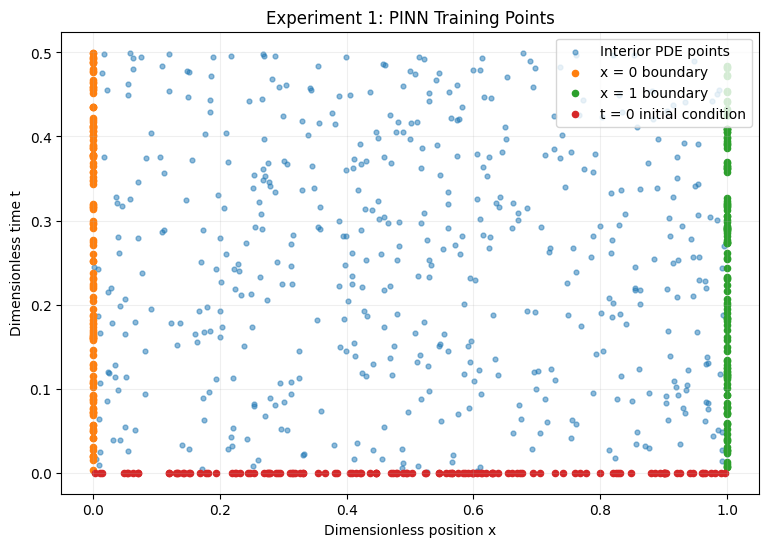

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    x_f.detach().cpu().numpy(),
    t_f.detach().cpu().numpy(),
    s=12,
    alpha=0.5,
    label="Interior PDE points"
)

plt.scatter(
    x_left.detach().cpu().numpy(),
    t_left.detach().cpu().numpy(),
    s=20,
    label="x = 0 boundary"
)

plt.scatter(
    x_right.detach().cpu().numpy(),
    t_right.detach().cpu().numpy(),
    s=20,
    label="x = 1 boundary"
)

plt.scatter(
    x_initial.detach().cpu().numpy(),
    t_initial.detach().cpu().numpy(),
    s=20,
    label="t = 0 initial condition"
)

plt.xlabel("Dimensionless position x")
plt.ylabel("Dimensionless time t")
plt.title("Experiment 1: PINN Training Points")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

## PINN Architecture

### FROM PAPER

The neural network contains:

Input:
(x,t)

5 hidden layers

50 neurons per hidden layer

Activation:
tanh

Output:
p(x,t)

The output layer uses a linear activation.

Weights are initialized using Glorot normal initialization.

The paper additionally multiplies the raw neural-network output by x:

p(x,t) = x N(x,t)

This guarantees:

p(0,t) = 0

for every value of the network parameters.

Therefore, the Dirichlet boundary at x = 0 is imposed as a hard
constraint.

In [ ]:
class ConsolidationPINN(nn.Module):

    def __init__(self):
        super().__init__()

        layers = []

        # Input layer: (x,t) -> 50
        layers.append(
            nn.Linear(2, HIDDEN_NEURONS)
        )
        layers.append(nn.Tanh())

        # Remaining hidden layers
        for _ in range(HIDDEN_LAYERS - 1):

            layers.append(
                nn.Linear(
                    HIDDEN_NEURONS,
                    HIDDEN_NEURONS
                )
            )

            layers.append(nn.Tanh())

        # Linear output
        layers.append(
            nn.Linear(
                HIDDEN_NEURONS,
                1
            )
        )

        self.network = nn.Sequential(*layers)

        # ==============================================
        # FROM PAPER:
        # Glorot normal initialization
        # ==============================================

        for layer in self.network:

            if isinstance(layer, nn.Linear):

                nn.init.xavier_normal_(
                    layer.weight
                )

                nn.init.zeros_(
                    layer.bias
                )


    def forward(self, x, t):

        inputs = torch.cat(
            [x, t],
            dim=1
        )

        raw_output = self.network(inputs)

        # ==============================================
        # FROM PAPER:
        # Multiply network output by x.
        #
        # This guarantees p(0,t) = 0.
        # ==============================================

        p = x * raw_output

        return p

In [ ]:
model1 = ConsolidationPINN().to(device)

optimizer_adam = optim.Adam(
    model1.parameters(),
    lr=LEARNING_RATE
)

print(model1)

ConsolidationPINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=50, bias=True)
    (1): Tanh()
    (2): Linear(in_features=50, out_features=50, bias=True)
    (3): Tanh()
    (4): Linear(in_features=50, out_features=50, bias=True)
    (5): Tanh()
    (6): Linear(in_features=50, out_features=50, bias=True)
    (7): Tanh()
    (8): Linear(in_features=50, out_features=50, bias=True)
    (9): Tanh()
    (10): Linear(in_features=50, out_features=1, bias=True)
  )
)


## Verification of the Hard Boundary Condition

Because the network output is multiplied by x, the prediction should
always satisfy:

p(0,t) = 0

even before training.

The following test verifies this property.

In [ ]:
test_t = torch.tensor(
    [[0.1],
     [0.2],
     [0.4]],
    dtype=torch.float32,
    device=device
)

test_x = torch.zeros_like(test_t)

with torch.no_grad():

    p_zero = model1(
        test_x,
        test_t
    )

print("Predictions at x = 0:")
print(p_zero.cpu().numpy())

Predictions at x = 0:
[[0.]
 [0.]
 [0.]]


## Physics Residual

The dimensionless governing equation is:

∂p/∂t - ∂²p/∂x² = 0

The PINN prediction p(x,t) is differentiated using automatic
differentiation.

The PDE residual is therefore defined as:

f(x,t) = ∂p/∂t - ∂²p/∂x²

For a solution that perfectly satisfies the governing equation:

f(x,t) = 0.

The physics loss is the mean squared PDE residual evaluated at the
interior collocation points.

In [ ]:
def experiment1_pde_residual(model, x, t):

    p = model(x, t)

    # First-order derivatives
    p_t = derivative(p, t)
    p_x = derivative(p, x)

    # Second-order spatial derivative
    p_xx = derivative(p_x, x)

    # PDE:
    # p_t - p_xx = 0

    residual = p_t - p_xx

    return residual

## Boundary and Initial Conditions

The remaining constraints are:

### Left boundary

p(0,t) = 0

This condition is already satisfied exactly by the output
transformation p = xN(x,t).

### Right boundary

∂p/∂x = 0 at x = 1

### Initial condition

p(x,0) = 1

The right boundary and initial condition are included in the PINN
boundary loss.

In [ ]:
def left_boundary_residual(model):

    p_left = model(
        x_left,
        t_left
    )

    return p_left


def right_boundary_residual(model):

    p_right = model(
        x_right,
        t_right
    )

    p_right_x = derivative(
        p_right,
        x_right
    )

    return p_right_x


def initial_condition_residual(model):

    p_initial = model(
        x_initial,
        t_initial
    )

    return p_initial - 1.0

## PINN Loss Function

The general PINN loss used by the paper is:

L = wf Lf + wb Lb + wd Ld

where:

Lf = governing-equation residual loss

Lb = boundary-condition loss

Ld = observation/data loss

Experiment 1 contains no observation-data loss.

### FROM PAPER

wf = 1/4

wb = 1/4

wd is not used.

### OUR IMPLEMENTATION CHOICE

The paper does not state exactly how the individual left-boundary,
right-boundary and initial-condition residuals are aggregated inside Lb.

In this implementation, all boundary and initial-condition residuals
are concatenated and their mean squared residual is used as Lb.

In [ ]:
def loss_experiment1(model):

    # ========================================================
    # PHYSICS LOSS Lf
    # ========================================================

    physics_residual = experiment1_pde_residual(
        model,
        x_f,
        t_f
    )

    loss_f = torch.mean(
        physics_residual ** 2
    )


    # ========================================================
    # BOUNDARY LOSS Lb
    # ========================================================

    r_left = left_boundary_residual(model)

    r_right = right_boundary_residual(model)

    r_initial = initial_condition_residual(model)


    # OUR IMPLEMENTATION CHOICE:
    # combine all boundary/initial residuals

    boundary_residuals = torch.cat(
        [
            r_left,
            r_right,
            r_initial
        ],
        dim=0
    )

    loss_b = torch.mean(
        boundary_residuals ** 2
    )


    # ========================================================
    # TOTAL LOSS - FROM PAPER
    # ========================================================

    total_loss = (
        W_F * loss_f
        +
        W_B * loss_b
    )

    return total_loss, loss_f, loss_b

## Initial Loss Check

Before training, the loss is evaluated once to verify that:

- the computational graph is valid,
- first- and second-order derivatives can be calculated,
- all tensor dimensions are compatible.

If this cell executes successfully, training can begin.

In [ ]:
initial_total_loss, initial_physics_loss, initial_boundary_loss = \
    loss_experiment1(model1)

print("Initial total loss   :", initial_total_loss.item())
print("Initial physics loss :", initial_physics_loss.item())
print("Initial boundary loss:", initial_boundary_loss.item())

Initial total loss   : 0.1364918202161789
Initial physics loss : 0.193126380443573
Initial boundary loss: 0.3528409004211426


## Adam Optimization

### FROM PAPER

The authors train Experiment 1 using:

Adam optimizer

Learning rate = 0.001

50,000 epochs

After Adam training, L-BFGS is used until convergence.

During development, a smaller number of epochs may be used to verify
that the implementation works. Final reported experiments should state
the actual number of epochs that were executed.

In [ ]:
# ============================================================
# DEVELOPMENT SETTING
#
# Use a smaller epoch count while debugging.
# This is NOT the paper's final training configuration.
# ============================================================

QUICK_RUN = False

if QUICK_RUN:
    ADAM_EPOCHS = 2000
else:
    ADAM_EPOCHS = ADAM_EPOCHS_PAPER

print("Adam epochs:", ADAM_EPOCHS)

Adam epochs: 50000


In [ ]:
loss_history_adam = []
physics_history_adam = []
boundary_history_adam = []

print("Starting Adam training...")
print("-" * 60)


for epoch in range(ADAM_EPOCHS):

    optimizer_adam.zero_grad()

    total_loss, loss_f, loss_b = \
        loss_experiment1(model1)

    total_loss.backward()

    optimizer_adam.step()


    # Save losses

    loss_history_adam.append(
        total_loss.item()
    )

    physics_history_adam.append(
        loss_f.item()
    )

    boundary_history_adam.append(
        loss_b.item()
    )


    # Print progress

    if (
        epoch == 0
        or (epoch + 1) % 500 == 0
    ):

        print(
            f"Epoch {epoch+1:5d} | "
            f"Total = {total_loss.item():.6e} | "
            f"PDE = {loss_f.item():.6e} | "
            f"Boundary = {loss_b.item():.6e}"
        )


print("-" * 60)
print("Adam training complete.")

Starting Adam training...
------------------------------------------------------------
Epoch     1 | Total = 1.364918e-01 | PDE = 1.931264e-01 | Boundary = 3.528409e-01
Epoch   500 | Total = 1.122111e-02 | PDE = 1.471597e-03 | Boundary = 4.341283e-02
Epoch  1000 | Total = 6.076446e-03 | PDE = 1.690638e-03 | Boundary = 2.261515e-02
Epoch  1500 | Total = 4.376054e-03 | PDE = 1.451413e-03 | Boundary = 1.605280e-02
Epoch  2000 | Total = 3.706375e-03 | PDE = 6.789446e-04 | Boundary = 1.414656e-02
Epoch  2500 | Total = 3.186133e-03 | PDE = 3.960912e-04 | Boundary = 1.234844e-02
Epoch  3000 | Total = 2.971150e-03 | PDE = 6.487979e-04 | Boundary = 1.123580e-02
Epoch  3500 | Total = 3.215881e-03 | PDE = 2.184824e-03 | Boundary = 1.067870e-02
Epoch  4000 | Total = 2.653080e-03 | PDE = 5.207871e-04 | Boundary = 1.009153e-02
Epoch  4500 | Total = 3.000615e-03 | PDE = 2.171232e-03 | Boundary = 9.831229e-03
Epoch  5000 | Total = 2.753382e-03 | PDE = 1.695829e-03 | Boundary = 9.317698e-03
Epoch  5500

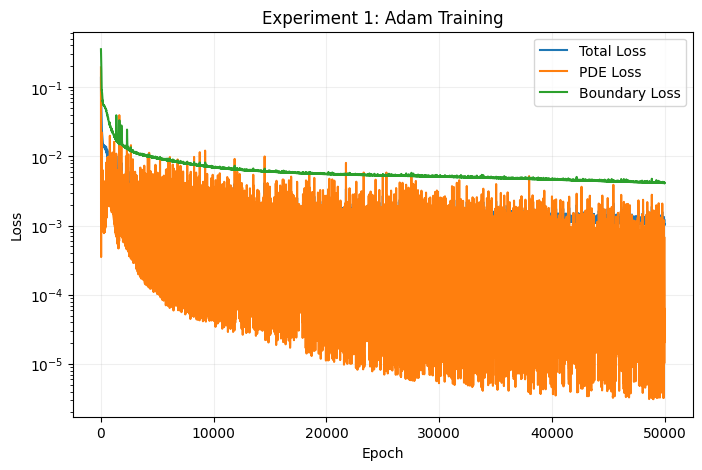

In [ ]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    loss_history_adam,
    label="Total Loss"
)

plt.semilogy(
    physics_history_adam,
    label="PDE Loss"
)

plt.semilogy(
    boundary_history_adam,
    label="Boundary Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Experiment 1: Adam Training")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

## L-BFGS Optimization

### FROM PAPER

After 50,000 Adam epochs, the authors use L-BFGS until convergence.

### NOT SPECIFIED BY THE PAPER

The authors do not report:

- L-BFGS learning rate
- maximum L-BFGS iterations
- history size
- convergence tolerances
- line-search configuration

### OUR IMPLEMENTATION CHOICE

PyTorch L-BFGS is used with explicitly stated settings below.
These settings are implementation choices rather than parameters
reported by the original paper.

In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
# PyTorch-specific L-BFGS configuration
# ============================================================

optimizer_lbfgs = torch.optim.LBFGS(
    model1.parameters(),
    lr=1.0,
    max_iter=2000,
    tolerance_grad=1e-9,
    tolerance_change=1e-12,
    history_size=100,
    line_search_fn="strong_wolfe"
)

loss_history_lbfgs = []

lbfgs_counter = [0]


def closure():

    optimizer_lbfgs.zero_grad()

    total_loss, loss_f, loss_b = \
        loss_experiment1(model1)

    total_loss.backward()

    loss_history_lbfgs.append(
        total_loss.item()
    )

    lbfgs_counter[0] += 1

    if lbfgs_counter[0] % 100 == 0:

        print(
            f"L-BFGS Iteration "
            f"{lbfgs_counter[0]:5d} | "
            f"Loss = "
            f"{total_loss.item():.6e}"
        )

    return total_loss

In [ ]:
print("Starting L-BFGS optimization...")

optimizer_lbfgs.step(closure)

print("L-BFGS complete.")
print(
    "L-BFGS closure evaluations:",
    lbfgs_counter[0]
)

Starting L-BFGS optimization...
L-BFGS Iteration   100 | Loss = 8.967930e-04
L-BFGS Iteration   200 | Loss = 6.940921e-04
L-BFGS Iteration   300 | Loss = 5.867208e-04
L-BFGS Iteration   400 | Loss = 5.213246e-04
L-BFGS Iteration   500 | Loss = 4.795067e-04
L-BFGS Iteration   600 | Loss = 4.536347e-04
L-BFGS Iteration   700 | Loss = 4.447670e-04
L-BFGS Iteration   800 | Loss = 4.380873e-04
L-BFGS Iteration   900 | Loss = 4.282401e-04
L-BFGS Iteration  1000 | Loss = 4.230010e-04
L-BFGS Iteration  1100 | Loss = 4.201202e-04
L-BFGS Iteration  1200 | Loss = 4.137454e-04
L-BFGS Iteration  1300 | Loss = 4.115207e-04
L-BFGS Iteration  1400 | Loss = 4.060355e-04
L-BFGS Iteration  1500 | Loss = 3.950729e-04
L-BFGS Iteration  1600 | Loss = 3.777107e-04
L-BFGS Iteration  1700 | Loss = 3.654775e-04
L-BFGS Iteration  1800 | Loss = 3.556071e-04
L-BFGS Iteration  1900 | Loss = 3.486905e-04
L-BFGS Iteration  2000 | Loss = 3.417139e-04
L-BFGS Iteration  2100 | Loss = 3.350740e-04
L-BFGS Iteration  2200 

## Analytical Reference Solution

The paper provides an analytical solution for the dimensionless
consolidation problem:

p(x,t) =
Σ [4/(mπ)] sin(mπx/2) exp(-m²π²t/4)

where the summation is taken over odd integers:

m = 1, 3, 5, 7, ...

The analytical solution is used as the reference for evaluating the
PINN prediction.

### OUR IMPLEMENTATION CHOICE

The analytical expression contains an infinite series.

The paper does not specify how many terms were retained numerically.

In this implementation, the series is truncated after the first
100 odd terms.

In [ ]:
def analytical_solution_exp1(
    x,
    t,
    n_terms=100
):

    solution = np.zeros_like(
        x,
        dtype=np.float64
    )

    for i in range(n_terms):

        # Odd values:
        # 1, 3, 5, 7, ...

        m = 2 * i + 1

        solution += (
            4.0 / (m * np.pi)
            *
            np.sin(
                m * np.pi * x / 2
            )
            *
            np.exp(
                -(m ** 2)
                * (np.pi ** 2)
                * t / 4
            )
        )

    return solution

## Test Set

### FROM PAPER

The authors use a test set containing 10,011 points.

The paper states that the physics residual is evaluated on the test set.
Because an analytical solution is available for Experiment 1, the mean
squared prediction error is also evaluated.

### OUR IMPLEMENTATION CHOICE

The paper does not specify the exact spatial and temporal coordinates of
the 10,011 test points.

We therefore sample 10,011 points uniformly from the experiment domain.

In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
# Uniform random test-set sampling
# ============================================================

rng_test = np.random.default_rng(123)

x_test = rng_test.random(
    (N_TEST, 1)
)

t_test = T_MAX * rng_test.random(
    (N_TEST, 1)
)


x_test_tensor = torch.tensor(
    x_test,
    dtype=torch.float32,
    device=device
)

t_test_tensor = torch.tensor(
    t_test,
    dtype=torch.float32,
    device=device
)

In [ ]:
with torch.no_grad():

    p_test_pred = model1(
        x_test_tensor,
        t_test_tensor
    ).cpu().numpy()


p_test_true = analytical_solution_exp1(
    x_test,
    t_test
)

In [ ]:
prediction_mse = np.mean(
    (p_test_pred - p_test_true) ** 2
)

max_absolute_error = np.max(
    np.abs(
        p_test_pred - p_test_true
    )
)

print("Experiment 1 Prediction Results")
print("-" * 40)

print(
    f"Prediction MSE      : "
    f"{prediction_mse:.6e}"
)

print(
    f"Maximum Abs. Error : "
    f"{max_absolute_error:.6e}"
)

Experiment 1 Prediction Results
----------------------------------------
Prediction MSE      : 4.997314e-04
Maximum Abs. Error : 3.508560e-01


In [ ]:
x_test_grad = torch.tensor(
    x_test,
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

t_test_grad = torch.tensor(
    t_test,
    dtype=torch.float32,
    device=device,
    requires_grad=True
)


test_residual = experiment1_pde_residual(
    model1,
    x_test_grad,
    t_test_grad
)

test_physics_loss = torch.mean(
    test_residual ** 2
).item()


print(
    f"Test PDE residual MSE: "
    f"{test_physics_loss:.6e}"
)

Test PDE residual MSE: 1.722145e+02


## Visualization of Experiment 1 Results

The reference paper presents four main outputs for Experiment 1:

1. Analytical/reference solution
2. PINN solution
3. Absolute error
4. Training convergence

The following plots reproduce the same types of information.

### OUR IMPLEMENTATION CHOICE

The exact plotting-grid resolution used by the original authors is not
reported.

A 101 × 101 grid is therefore used for visualization.

In [ ]:
# OUR IMPLEMENTATION CHOICE

NX = 101
NT = 101


x_plot = np.linspace(
    0,
    1,
    NX
)

t_plot = np.linspace(
    0,
    T_MAX,
    NT
)


X_grid, T_grid = np.meshgrid(
    x_plot,
    t_plot
)

In [ ]:
# Analytical reference

P_true = analytical_solution_exp1(
    X_grid,
    T_grid
)


# Neural-network prediction

x_grid_tensor = torch.tensor(
    X_grid.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)

t_grid_tensor = torch.tensor(
    T_grid.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)


with torch.no_grad():

    P_pred = model1(
        x_grid_tensor,
        t_grid_tensor
    ).cpu().numpy()


P_pred = P_pred.reshape(
    X_grid.shape
)


# Absolute error

P_error = np.abs(
    P_true - P_pred
)

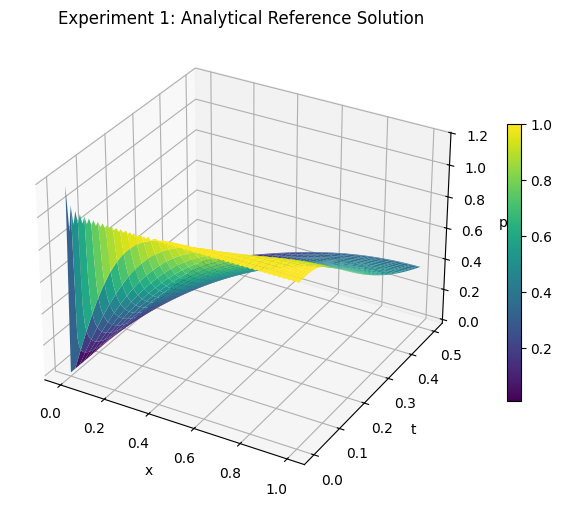

In [ ]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X_grid,
    T_grid,
    P_true,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel("p")
ax.set_title(
    "Experiment 1: Analytical Reference Solution"
)

fig.colorbar(
    surface,
    shrink=0.6
)

plt.show()

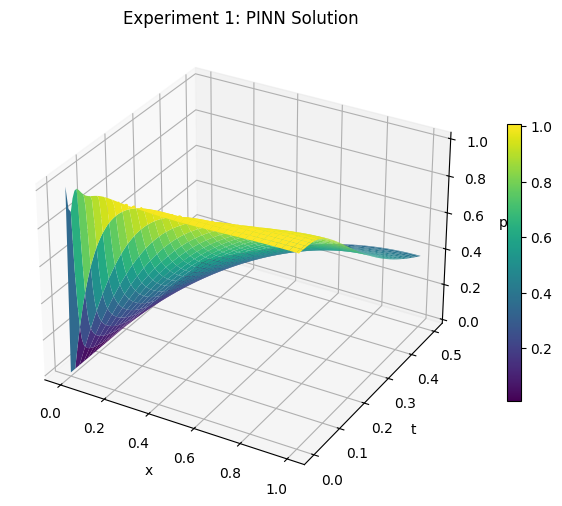

In [ ]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X_grid,
    T_grid,
    P_pred,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel("p")
ax.set_title(
    "Experiment 1: PINN Solution"
)

fig.colorbar(
    surface,
    shrink=0.6
)

plt.show()

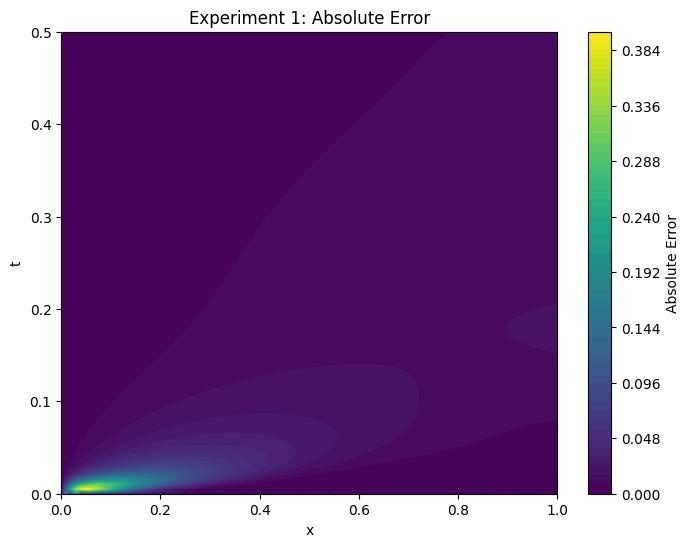

In [ ]:
plt.figure(figsize=(8, 6))

plt.contourf(
    X_grid,
    T_grid,
    P_error,
    levels=50,
    cmap="viridis"
)

plt.colorbar(
    label="Absolute Error"
)

plt.xlabel("x")
plt.ylabel("t")

plt.title(
    "Experiment 1: Absolute Error"
)

plt.show()

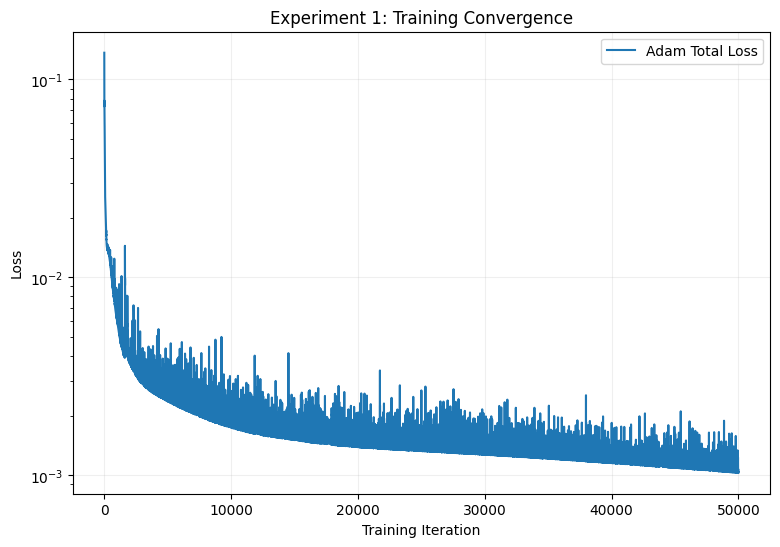

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    loss_history_adam,
    label="Adam Total Loss"
)

plt.xlabel("Training Iteration")
plt.ylabel("Loss")

plt.title(
    "Experiment 1: Training Convergence"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Experiment 1 Summary

A Physics-Informed Neural Network was used to solve the dimensionless
one-dimensional consolidation equation.

The model was trained by minimizing:

- the governing PDE residual,
- the spatial-boundary residuals,
- the initial-condition residual.

The left Dirichlet boundary condition was enforced directly through
the output transformation:

p(x,t) = xN(x,t).

The trained PINN was evaluated against the analytical solution supplied
in the reference paper.

The final evaluation includes:

- prediction mean squared error,
- test PDE residual,
- maximum absolute error,
- comparison of analytical and PINN solutions,
- spatial-temporal absolute-error distribution,
- training convergence.

In [ ]:
print("=" * 55)
print("EXPERIMENT 1 FINAL RESULTS")
print("=" * 55)

print(
    f"Prediction MSE       : "
    f"{prediction_mse:.6e}"
)

print(
    f"Test PDE Loss        : "
    f"{test_physics_loss:.6e}"
)

print(
    f"Maximum Abs. Error   : "
    f"{max_absolute_error:.6e}"
)

print("=" * 55)

EXPERIMENT 1 FINAL RESULTS
Prediction MSE       : 4.997314e-04
Test PDE Loss        : 1.722145e+02
Maximum Abs. Error   : 3.508560e-01


### Difference Between the Paper and Our Implementation

The reference paper states that all predicted output values in
Experiment 1 were enforced to remain between 0 and 1 and that the
initial condition was strictly satisfied.

However, the report does not specify the mathematical transformation or
implementation used to enforce these properties.

The only explicitly documented output transformation is:

p(x,t) = xN(x,t),

which exactly satisfies the boundary condition at x = 0.

Therefore, this replication implements the documented output
transformation and imposes the initial condition through the PINN
boundary loss.

This detail may differ from the unpublished implementation used by the
authors.

## Experiment 1 Diagnostics

### OUR IMPLEMENTATION ADDITION

The test PDE residual is much larger than the training PDE loss. The cells
below check where the error is concentrated and plot the full
Adam + L-BFGS convergence history.

The solution has a sharp gradient near x = 0 at small t, because the initial
condition p = 1 meets the boundary condition p = 0 there.

In [ ]:
# Where is the error concentrated?
res2 = (test_residual.detach().cpu().numpy().ravel()) ** 2
err2 = ((p_test_pred - p_test_true).ravel()) ** 2
xs, ts = x_test.ravel(), t_test.ravel()

corner = (xs < 0.05) | (ts < 0.02)   # sharp-gradient region (our choice of cutoff)

print(f"Fraction of test points in corner region : {corner.mean():.3f}")
print(f"PDE residual MSE  (all points)           : {res2.mean():.4e}")
print(f"PDE residual MSE  (corner region)        : {res2[corner].mean():.4e}")
print(f"PDE residual MSE  (outside corner)       : {res2[~corner].mean():.4e}")
print(f"Median PDE residual^2 (all points)       : {np.median(res2):.4e}")
print()
print(f"Prediction MSE    (all points)           : {err2.mean():.4e}")
print(f"Prediction MSE    (corner region)        : {err2[corner].mean():.4e}")
print(f"Prediction MSE    (outside corner)       : {err2[~corner].mean():.4e}")

worst = np.argsort(res2)[-5:][::-1]
print("\nWorst 5 residual points (x, t, residual^2):")
for i in worst:
    print(f"  x={xs[i]:.4f}, t={ts[i]:.4f}, r^2={res2[i]:.3e}")

Fraction of test points in corner region : 0.082
PDE residual MSE  (all points)           : 1.7221e+02
PDE residual MSE  (corner region)        : 2.0999e+03
PDE residual MSE  (outside corner)       : 1.1362e-03
Median PDE residual^2 (all points)       : 2.0748e-05

Prediction MSE    (all points)           : 4.9973e-04
Prediction MSE    (corner region)        : 3.5899e-03
Prediction MSE    (outside corner)       : 2.2367e-04

Worst 5 residual points (x, t, residual^2):
  x=0.0006, t=0.0043, r^2=1.003e+06
  x=0.0392, t=0.0013, r^2=1.309e+05
  x=0.0209, t=0.0027, r^2=1.223e+05
  x=0.0200, t=0.0034, r^2=9.750e+04
  x=0.0500, t=0.0011, r^2=9.623e+04


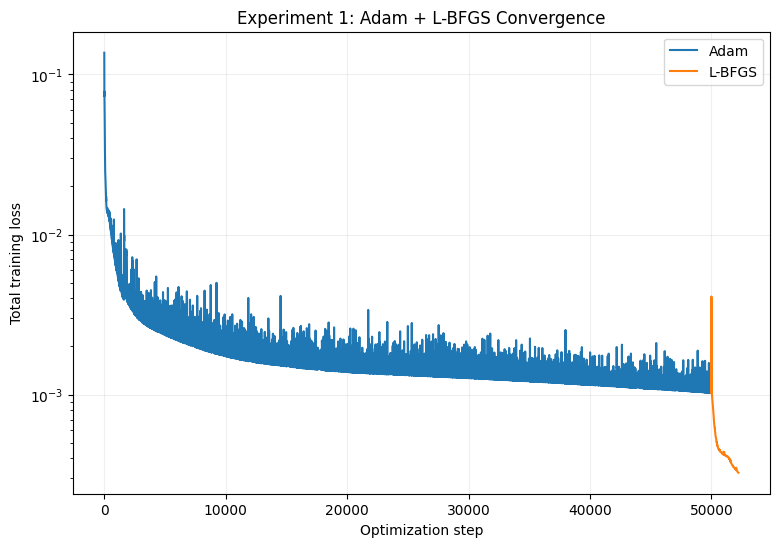

In [ ]:
# Full convergence: Adam + L-BFGS
plt.figure(figsize=(9, 6))

n_adam = len(loss_history_adam)
plt.semilogy(np.arange(n_adam), loss_history_adam, label="Adam")
plt.semilogy(
    n_adam + np.arange(len(loss_history_lbfgs)),
    loss_history_lbfgs,
    label="L-BFGS"
)

plt.xlabel("Optimization step")
plt.ylabel("Total training loss")
plt.title("Experiment 1: Adam + L-BFGS Convergence")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

### Interpretation

If the residual outside the corner region is small, the large test PDE loss
comes from the boundary-layer / initial-condition singularity at the corner,
where a network trained on only 500 collocation points cannot resolve the
sharp gradient. The paper also reports its largest error near the origin.

# Experiment 2: Two-Dimensional Steady-State Heat Conduction

The second experiment reproduces the steady-state heat-conduction
problem presented in Section 4.2 of the reference paper.

For constant heat-conduction coefficient, constant heat source and
constant boundary temperature, the temperature field satisfies
Poisson's equation.

The governing dimensionless equation is:

∂²T/∂x² + ∂²T/∂y² + 1 = 0

over the square domain:

-1 < x < 1

-1 < y < 1

with the Dirichlet boundary condition:

T = 0

on the entire boundary of the square.

## Experiment 2 Configuration

### FROM PAPER

The authors report:

- 1500 interior residual points
- 500 boundary points
- 10,000 test points
- Physics loss weight: wf = 1/2
- Boundary loss weight: wb = 1/2
- No observation-data loss
- 4 hidden layers
- 50 neurons per hidden layer
- Learning rate = 0.0005
- Glorot uniform initialization
- No transformation applied to the neural-network output

The paper states that all remaining settings are the same as in
Experiment 1.

Therefore, this implementation also uses:

- tanh hidden-layer activation
- Adam optimization followed by L-BFGS

In [ ]:
# ============================================================
# EXPERIMENT 2
# PARAMETERS REPORTED IN THE PAPER
# ============================================================

N_F_EXP2 = 1500
N_B_EXP2 = 500

N_TEST_EXP2 = 10000

HIDDEN_LAYERS_EXP2 = 4
HIDDEN_NEURONS_EXP2 = 50

LEARNING_RATE_EXP2 = 0.0005

W_F_EXP2 = 1 / 2
W_B_EXP2 = 1 / 2

# "Remaining settings same as Experiment 1"
ADAM_EPOCHS_EXP2_PAPER = 50000

print("Experiment 2 configuration loaded.")

Experiment 2 configuration loaded.


### Implementation Detail: Boundary Sampling

The reference paper specifies 500 total boundary points but does not
describe how those points are distributed among the four edges:

x = -1

x = 1

y = -1

y = 1

### OUR IMPLEMENTATION CHOICE

The 500 boundary points are divided equally among the four edges:

125 points per edge.

In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
# Equal split of the 500 boundary points
# ============================================================

N_EDGE = N_B_EXP2 // 4

print("Points per edge:", N_EDGE)
print("Total boundary points:", 4 * N_EDGE)

Points per edge: 125
Total boundary points: 500


## Training-Point Generation

As in Experiment 1, this forward PINN does not require a conventional
labelled training dataset.

The neural network is constrained using:

1. Interior collocation points where Poisson's equation must hold.
2. Boundary points where T = 0 must hold.

The reference paper samples these points randomly.

In [ ]:
# ============================================================
# INTERIOR RESIDUAL POINTS
#
# FROM PAPER:
# 1500 randomly sampled points
#
# Domain:
# -1 < x < 1
# -1 < y < 1
# ============================================================

x_f_exp2 = -1 + 2 * torch.rand(
    N_F_EXP2, 1,
    device=device
)

y_f_exp2 = -1 + 2 * torch.rand(
    N_F_EXP2, 1,
    device=device
)

# Convert to independent leaf tensors for autograd
x_f_exp2.requires_grad_(True)
y_f_exp2.requires_grad_(True)

print("Interior points:", x_f_exp2.shape[0])
print("x leaf:", x_f_exp2.is_leaf)
print("y leaf:", y_f_exp2.is_leaf)

Interior points: 1500
x leaf: True
y leaf: True


In [ ]:
# ============================================================
# BOUNDARY POINTS
#
# OUR IMPLEMENTATION CHOICE:
# 125 randomly sampled points on each edge
# ============================================================

# ------------------------------------------------------------
# LEFT: x = -1
# ------------------------------------------------------------

x_left_exp2 = -torch.ones(
    N_EDGE, 1,
    device=device
)

y_left_exp2 = -1 + 2 * torch.rand(
    N_EDGE, 1,
    device=device
)


# ------------------------------------------------------------
# RIGHT: x = 1
# ------------------------------------------------------------

x_right_exp2 = torch.ones(
    N_EDGE, 1,
    device=device
)

y_right_exp2 = -1 + 2 * torch.rand(
    N_EDGE, 1,
    device=device
)


# ------------------------------------------------------------
# BOTTOM: y = -1
# ------------------------------------------------------------

x_bottom_exp2 = -1 + 2 * torch.rand(
    N_EDGE, 1,
    device=device
)

y_bottom_exp2 = -torch.ones(
    N_EDGE, 1,
    device=device
)


# ------------------------------------------------------------
# TOP: y = 1
# ------------------------------------------------------------

x_top_exp2 = -1 + 2 * torch.rand(
    N_EDGE, 1,
    device=device
)

y_top_exp2 = torch.ones(
    N_EDGE, 1,
    device=device
)

print(
    "Boundary points:",
    len(x_left_exp2)
    + len(x_right_exp2)
    + len(x_bottom_exp2)
    + len(x_top_exp2)
)

Boundary points: 500


## Visualization of Training Points

### OUR IMPLEMENTATION ADDITION

The paper does not show the sampled collocation points.

The following plot is included to verify that the interior and boundary
samples cover the required two-dimensional domain.

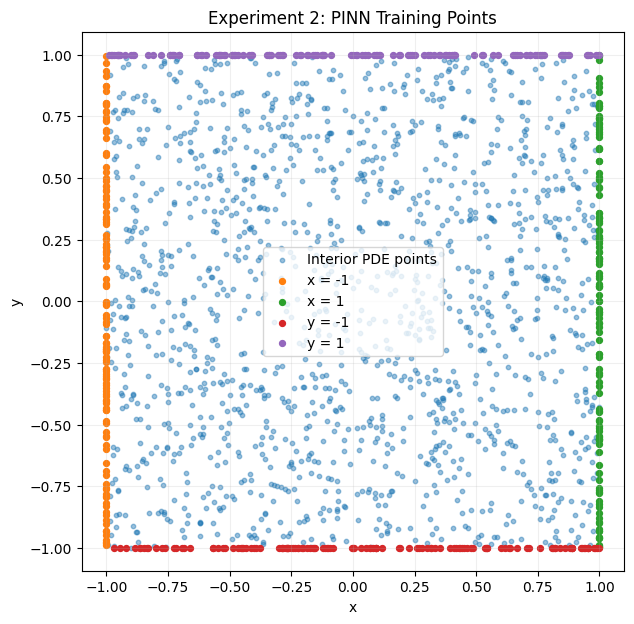

In [ ]:
plt.figure(figsize=(7, 7))

plt.scatter(
    x_f_exp2.detach().cpu(),
    y_f_exp2.detach().cpu(),
    s=10,
    alpha=0.45,
    label="Interior PDE points"
)

plt.scatter(
    x_left_exp2.cpu(),
    y_left_exp2.cpu(),
    s=18,
    label="x = -1"
)

plt.scatter(
    x_right_exp2.cpu(),
    y_right_exp2.cpu(),
    s=18,
    label="x = 1"
)

plt.scatter(
    x_bottom_exp2.cpu(),
    y_bottom_exp2.cpu(),
    s=18,
    label="y = -1"
)

plt.scatter(
    x_top_exp2.cpu(),
    y_top_exp2.cpu(),
    s=18,
    label="y = 1"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title(
    "Experiment 2: PINN Training Points"
)

plt.legend()
plt.grid(alpha=0.2)
plt.axis("equal")

plt.show()

## PINN Architecture

### FROM PAPER

Experiment 2 uses:

Input:
(x,y)

4 hidden layers

50 neurons per hidden layer

Glorot uniform initialization

No transformation of the network output

The remaining settings are stated to be the same as Experiment 1,
so tanh activation is used in the hidden layers and the output layer
is linear.

The network therefore directly predicts:

T(x,y)

In [ ]:
class HeatConductionPINN(nn.Module):

    def __init__(self):
        super().__init__()

        layers = []

        # Input: (x,y) -> 50
        layers.append(
            nn.Linear(
                2,
                HIDDEN_NEURONS_EXP2
            )
        )

        layers.append(nn.Tanh())

        # Remaining 3 hidden layers
        for _ in range(
            HIDDEN_LAYERS_EXP2 - 1
        ):

            layers.append(
                nn.Linear(
                    HIDDEN_NEURONS_EXP2,
                    HIDDEN_NEURONS_EXP2
                )
            )

            layers.append(nn.Tanh())

        # Linear output
        layers.append(
            nn.Linear(
                HIDDEN_NEURONS_EXP2,
                1
            )
        )

        self.network = nn.Sequential(*layers)

        # ==============================================
        # FROM PAPER:
        # Glorot UNIFORM initialization
        # ==============================================

        for layer in self.network:

            if isinstance(layer, nn.Linear):

                nn.init.xavier_uniform_(
                    layer.weight
                )

                nn.init.zeros_(
                    layer.bias
                )


    def forward(self, x, y):

        inputs = torch.cat(
            [x, y],
            dim=1
        )

        # FROM PAPER:
        # No output transformation
        T = self.network(inputs)

        return T

In [ ]:
model2 = HeatConductionPINN().to(device)

optimizer_adam_exp2 = optim.Adam(
    model2.parameters(),
    lr=LEARNING_RATE_EXP2
)

print(model2)

HeatConductionPINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=50, bias=True)
    (1): Tanh()
    (2): Linear(in_features=50, out_features=50, bias=True)
    (3): Tanh()
    (4): Linear(in_features=50, out_features=50, bias=True)
    (5): Tanh()
    (6): Linear(in_features=50, out_features=50, bias=True)
    (7): Tanh()
    (8): Linear(in_features=50, out_features=1, bias=True)
  )
)


## Physics Residual

The governing equation is:

∂²T/∂x² + ∂²T/∂y² + 1 = 0

The PINN therefore computes:

Txx = ∂²T/∂x²

Tyy = ∂²T/∂y²

using automatic differentiation.

The PDE residual is:

f(x,y) = Txx + Tyy + 1

For an exact solution:

f(x,y) = 0.

In [ ]:
def experiment2_pde_residual(
    model,
    x,
    y
):

    T = model(x, y)

    T_x = derivative(T, x)
    T_y = derivative(T, y)

    T_xx = derivative(T_x, x)
    T_yy = derivative(T_y, y)

    residual = (
        T_xx
        + T_yy
        + 1.0
    )

    return residual

## Boundary Condition

The boundary condition is:

T = 0

on all four edges of the domain.

Unlike Experiment 1, the paper states that no output transformation is
applied.

Therefore, the Dirichlet boundary condition is enforced through the
boundary loss rather than being built directly into the architecture.

In [ ]:
def experiment2_boundary_values(model):

    T_left = model(
        x_left_exp2,
        y_left_exp2
    )

    T_right = model(
        x_right_exp2,
        y_right_exp2
    )

    T_bottom = model(
        x_bottom_exp2,
        y_bottom_exp2
    )

    T_top = model(
        x_top_exp2,
        y_top_exp2
    )

    return torch.cat(
        [
            T_left,
            T_right,
            T_bottom,
            T_top
        ],
        dim=0
    )

## Experiment 2 PINN Loss

### FROM PAPER

The loss weights are:

wf = 1/2

wb = 1/2

No observation-data loss is used.

Therefore:

L = (1/2)Lf + (1/2)Lb

where:

Lf is the mean squared PDE residual,

and

Lb is the mean squared boundary-condition error.

In [ ]:
def loss_experiment2(model):

    # ========================================================
    # PHYSICS LOSS
    # ========================================================

    residual_f = experiment2_pde_residual(
        model,
        x_f_exp2,
        y_f_exp2
    )

    loss_f = torch.mean(
        residual_f ** 2
    )


    # ========================================================
    # BOUNDARY LOSS
    # T = 0
    # ========================================================

    T_boundary = experiment2_boundary_values(
        model
    )

    loss_b = torch.mean(
        T_boundary ** 2
    )


    # ========================================================
    # TOTAL LOSS - FROM PAPER
    # ========================================================

    total_loss = (
        W_F_EXP2 * loss_f
        +
        W_B_EXP2 * loss_b
    )

    return total_loss, loss_f, loss_b

## Initial Loss Check

Before training, the Experiment 2 loss is evaluated once to confirm
that the second-order derivatives and boundary terms are calculated
correctly.

All returned values should be finite.

In [ ]:
initial_total_exp2, \
initial_pde_exp2, \
initial_boundary_exp2 = loss_experiment2(
    model2
)

print(
    "Initial total loss   :",
    initial_total_exp2.item()
)

print(
    "Initial physics loss :",
    initial_pde_exp2.item()
)

print(
    "Initial boundary loss:",
    initial_boundary_exp2.item()
)

Initial total loss   : 0.5192511677742004
Initial physics loss : 1.0088764429092407
Initial boundary loss: 0.0296259056776762


## Adam Optimization

The paper states that the remaining training settings are the same as
Experiment 1.

Experiment 1 uses Adam for 50,000 epochs followed by L-BFGS.

Experiment 2 changes the Adam learning rate to:

0.0005

### Development Run

Before running the full paper configuration, a shorter Adam run is used
to verify that the loss decreases and that the PINN learns the expected
temperature distribution.

In [ ]:
# ============================================================
# DEVELOPMENT MODE
# ============================================================

QUICK_RUN_EXP2 = True

if QUICK_RUN_EXP2:
    ADAM_EPOCHS_EXP2 = 2000
else:
    ADAM_EPOCHS_EXP2 = \
        ADAM_EPOCHS_EXP2_PAPER

print(
    "Experiment 2 Adam epochs:",
    ADAM_EPOCHS_EXP2
)

Experiment 2 Adam epochs: 2000


In [ ]:
loss_history_exp2 = []
physics_history_exp2 = []
boundary_history_exp2 = []

print(
    "Starting Experiment 2 Adam training..."
)

print("-" * 60)


for epoch in range(
    ADAM_EPOCHS_EXP2
):

    optimizer_adam_exp2.zero_grad()

    total_loss, \
    loss_f, \
    loss_b = loss_experiment2(
        model2
    )

    total_loss.backward()

    optimizer_adam_exp2.step()


    loss_history_exp2.append(
        total_loss.item()
    )

    physics_history_exp2.append(
        loss_f.item()
    )

    boundary_history_exp2.append(
        loss_b.item()
    )


    if (
        epoch == 0
        or (epoch + 1) % 500 == 0
    ):

        print(
            f"Epoch {epoch+1:5d} | "
            f"Total = "
            f"{total_loss.item():.6e} | "
            f"PDE = "
            f"{loss_f.item():.6e} | "
            f"Boundary = "
            f"{loss_b.item():.6e}"
        )


print("-" * 60)

print(
    "Experiment 2 Adam training complete."
)

Starting Experiment 2 Adam training...
------------------------------------------------------------
Epoch     1 | Total = 5.192512e-01 | PDE = 1.008876e+00 | Boundary = 2.962591e-02
Epoch   500 | Total = 1.961804e-03 | PDE = 4.162097e-04 | Boundary = 3.507398e-03
Epoch  1000 | Total = 1.240403e-03 | PDE = 5.340147e-04 | Boundary = 1.946792e-03
Epoch  1500 | Total = 4.163536e-04 | PDE = 3.351583e-04 | Boundary = 4.975490e-04
Epoch  2000 | Total = 1.881612e-04 | PDE = 1.929698e-04 | Boundary = 1.833526e-04
------------------------------------------------------------
Experiment 2 Adam training complete.


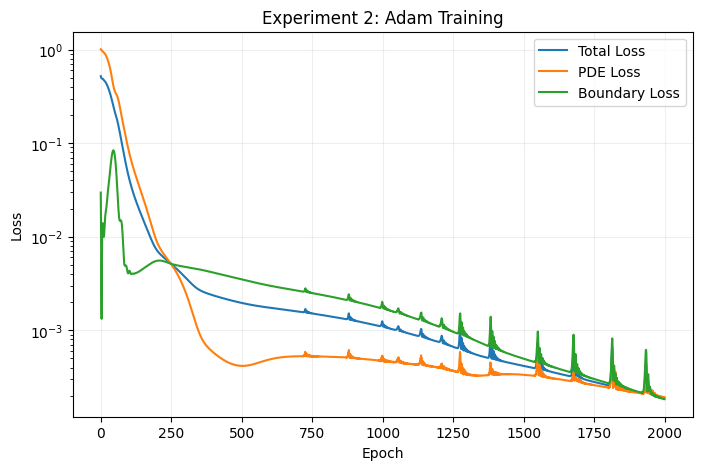

In [ ]:
plt.figure(figsize=(8, 5))

plt.semilogy(
    loss_history_exp2,
    label="Total Loss"
)

plt.semilogy(
    physics_history_exp2,
    label="PDE Loss"
)

plt.semilogy(
    boundary_history_exp2,
    label="Boundary Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Experiment 2: Adam Training"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Numerical Reference Solution

The reference paper compares the PINN solution with a high-accuracy
finite-element solution obtained using the deal.II finite-element
library.

### OUR IMPLEMENTATION CHOICE

To avoid introducing an external finite-element framework, this
replication uses a finite-difference method to independently solve the
same Poisson equation:

∂²T/∂x² + ∂²T/∂y² + 1 = 0

with:

T = 0

on the boundary.

This numerical solution is used only as the validation reference.
The PINN formulation itself is unchanged.

### Finite-Difference Approximation

For a uniform grid with spacing h, the two-dimensional Laplacian is
approximated using:

(T[i+1,j] + T[i-1,j] + T[i,j+1] + T[i,j-1] - 4T[i,j]) / h²

Substituting this into:

∇²T + 1 = 0

gives the iterative update:

T[i,j] =
1/4 ×
(T[i+1,j] + T[i-1,j] + T[i,j+1] + T[i,j-1] + h²)

The boundary values remain fixed at zero.

In [ ]:
# ============================================================
# FINITE-DIFFERENCE REFERENCE
#
# OUR IMPLEMENTATION CHOICE
# ============================================================

N_GRID_EXP2 = 81

x_fd = np.linspace(
    -1,
    1,
    N_GRID_EXP2
)

y_fd = np.linspace(
    -1,
    1,
    N_GRID_EXP2
)

h = x_fd[1] - x_fd[0]

# Initial temperature field
# Boundary values automatically remain zero

T_fd = np.zeros(
    (N_GRID_EXP2, N_GRID_EXP2),
    dtype=np.float64
)

MAX_ITER_FD = 20000
TOL_FD = 1e-8


for iteration in range(MAX_ITER_FD):

    T_old = T_fd.copy()

    # Jacobi finite-difference update
    T_fd[1:-1, 1:-1] = 0.25 * (
        T_old[2:, 1:-1]
        +
        T_old[:-2, 1:-1]
        +
        T_old[1:-1, 2:]
        +
        T_old[1:-1, :-2]
        +
        h**2
    )

    max_change = np.max(
        np.abs(T_fd - T_old)
    )

    if max_change < TOL_FD:

        print(
            "Finite-difference solver converged at "
            f"iteration {iteration + 1}"
        )

        break

else:

    print(
        "Finite-difference solver reached maximum iterations."
    )


print(
    "Maximum reference temperature:",
    np.max(T_fd)
)

Finite-difference solver converged at iteration 13148
Maximum reference temperature: 0.29463618205765335


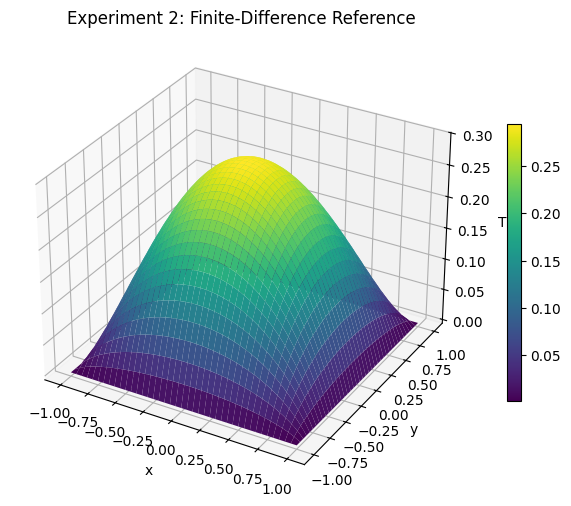

In [ ]:
X_fd, Y_fd = np.meshgrid(
    x_fd,
    y_fd
)


fig = plt.figure(
    figsize=(9, 6)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X_fd,
    Y_fd,
    T_fd,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("T")

ax.set_title(
    "Experiment 2: Finite-Difference Reference"
)

fig.colorbar(
    surface,
    shrink=0.6
)

plt.show()

## PINN Prediction on the Reference Grid

The trained PINN is now evaluated at the same grid locations as the
finite-difference reference.

This allows direct comparison between:

- numerical reference temperature,
- PINN temperature,
- absolute prediction error.

In [ ]:
x_grid_exp2 = torch.tensor(
    X_fd.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)

y_grid_exp2 = torch.tensor(
    Y_fd.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)


with torch.no_grad():

    T_pinn_exp2 = model2(
        x_grid_exp2,
        y_grid_exp2
    ).cpu().numpy()


T_pinn_exp2 = T_pinn_exp2.reshape(
    X_fd.shape
)


T_error_exp2 = np.abs(
    T_fd - T_pinn_exp2
)

In [ ]:
mse_exp2_quick = np.mean(
    (T_fd - T_pinn_exp2) ** 2
)

max_error_exp2_quick = np.max(
    T_error_exp2
)


print(
    "Experiment 2 Quick-Run Validation"
)

print("-" * 45)

print(
    f"MSE vs FD reference : "
    f"{mse_exp2_quick:.6e}"
)

print(
    f"Maximum abs error   : "
    f"{max_error_exp2_quick:.6e}"
)

print(
    f"Reference max T     : "
    f"{np.max(T_fd):.6f}"
)

print(
    f"PINN max T          : "
    f"{np.max(T_pinn_exp2):.6f}"
)

Experiment 2 Quick-Run Validation
---------------------------------------------
MSE vs FD reference : 4.992395e-05
Maximum abs error   : 4.335213e-02
Reference max T     : 0.294636
PINN max T          : 0.300087


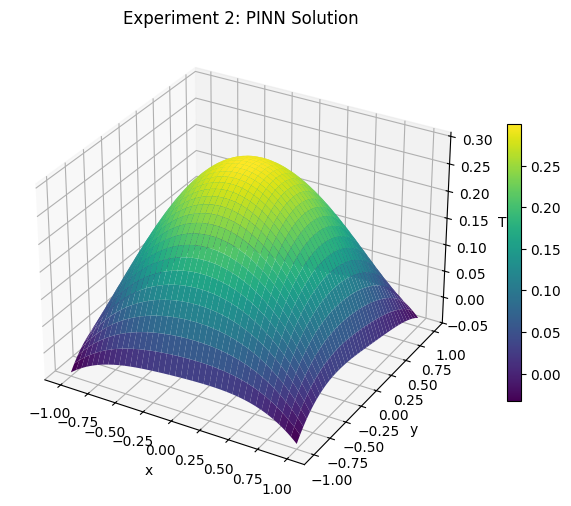

In [ ]:
fig = plt.figure(
    figsize=(9, 6)
)

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X_fd,
    Y_fd,
    T_pinn_exp2,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("T")

ax.set_title(
    "Experiment 2: PINN Solution"
)

fig.colorbar(
    surface,
    shrink=0.6
)

plt.show()

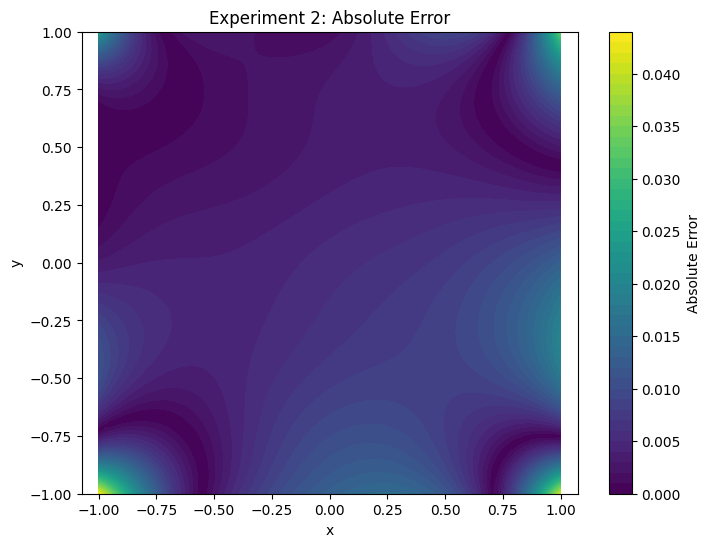

In [ ]:
plt.figure(
    figsize=(8, 6)
)

plt.contourf(
    X_fd,
    Y_fd,
    T_error_exp2,
    levels=50,
    cmap="viridis"
)

plt.colorbar(
    label="Absolute Error"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Experiment 2: Absolute Error"
)

plt.axis("equal")

plt.show()

## Final Training Paper Configuration

The development run confirmed that the Experiment 2 PINN learns the
expected heat-conduction solution.

A fresh neural network is now trained using the configuration reported
in the reference paper.

### FROM PAPER

- Adam learning rate = 0.0005
- 50,000 Adam epochs, since the remaining settings are stated to be
  the same as Experiment 1
- L-BFGS optimization after Adam
- Glorot uniform initialization

The model is reinitialized before the final run so that the 2,000-epoch
development run is not included in the final training count.

In [ ]:
# ============================================================
# FINAL EXPERIMENT 2 MODEL
# Fresh model so the quick 2000 epochs are not counted
# ============================================================

model2 = HeatConductionPINN().to(device)

optimizer_adam_exp2 = optim.Adam(
    model2.parameters(),
    lr=LEARNING_RATE_EXP2
)

print(model2)

HeatConductionPINN(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=50, bias=True)
    (1): Tanh()
    (2): Linear(in_features=50, out_features=50, bias=True)
    (3): Tanh()
    (4): Linear(in_features=50, out_features=50, bias=True)
    (5): Tanh()
    (6): Linear(in_features=50, out_features=50, bias=True)
    (7): Tanh()
    (8): Linear(in_features=50, out_features=1, bias=True)
  )
)


In [ ]:
ADAM_EPOCHS_EXP2 = 50000

print(
    "Final Experiment 2 Adam epochs:",
    ADAM_EPOCHS_EXP2
)

Final Experiment 2 Adam epochs: 50000


In [ ]:
loss_history_exp2 = []
physics_history_exp2 = []
boundary_history_exp2 = []

print(
    "Starting final Experiment 2 Adam training..."
)

print("-" * 60)


for epoch in range(ADAM_EPOCHS_EXP2):

    optimizer_adam_exp2.zero_grad()

    total_loss, loss_f, loss_b = \
        loss_experiment2(model2)

    total_loss.backward()

    optimizer_adam_exp2.step()


    loss_history_exp2.append(
        total_loss.item()
    )

    physics_history_exp2.append(
        loss_f.item()
    )

    boundary_history_exp2.append(
        loss_b.item()
    )


    if (
        epoch == 0
        or (epoch + 1) % 1000 == 0
    ):

        print(
            f"Epoch {epoch+1:5d} | "
            f"Total = {total_loss.item():.6e} | "
            f"PDE = {loss_f.item():.6e} | "
            f"Boundary = {loss_b.item():.6e}"
        )


print("-" * 60)
print("Final Adam training complete.")

Starting final Experiment 2 Adam training...
------------------------------------------------------------
Epoch     1 | Total = 5.706849e-01 | PDE = 1.022265e+00 | Boundary = 1.191050e-01
Epoch  1000 | Total = 1.424428e-03 | PDE = 6.390383e-04 | Boundary = 2.209818e-03
Epoch  2000 | Total = 1.505442e-04 | PDE = 1.761043e-04 | Boundary = 1.249842e-04
Epoch  3000 | Total = 4.120717e-05 | PDE = 5.061769e-05 | Boundary = 3.179664e-05
Epoch  4000 | Total = 2.372089e-05 | PDE = 1.983980e-05 | Boundary = 2.760197e-05
Epoch  5000 | Total = 1.657932e-05 | PDE = 1.218724e-05 | Boundary = 2.097141e-05
Epoch  6000 | Total = 1.416735e-05 | PDE = 8.336970e-06 | Boundary = 1.999772e-05
Epoch  7000 | Total = 2.025230e-04 | PDE = 2.185795e-04 | Boundary = 1.864664e-04
Epoch  8000 | Total = 1.234897e-05 | PDE = 5.506729e-06 | Boundary = 1.919122e-05
Epoch  9000 | Total = 1.188699e-05 | PDE = 4.750543e-06 | Boundary = 1.902344e-05
Epoch 10000 | Total = 1.540232e-05 | PDE = 7.553781e-06 | Boundary = 2.325

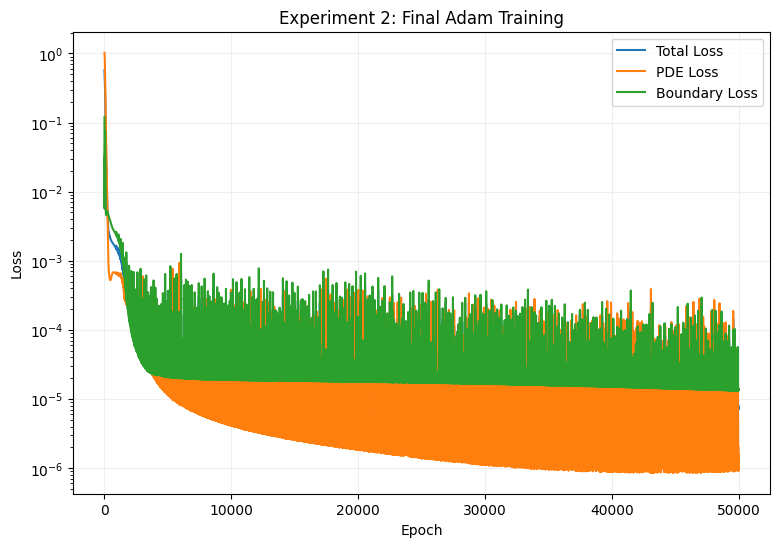

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    loss_history_exp2,
    label="Total Loss"
)

plt.semilogy(
    physics_history_exp2,
    label="PDE Loss"
)

plt.semilogy(
    boundary_history_exp2,
    label="Boundary Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Experiment 2: Final Adam Training"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## L-BFGS Optimization

### FROM PAPER

Experiment 2 uses the remaining optimization settings from Experiment 1.

Experiment 1 uses Adam followed by L-BFGS until convergence.

### OUR IMPLEMENTATION CHOICE

The paper does not provide the PyTorch-specific L-BFGS parameters.

The following settings are therefore implementation choices and are
the same configuration used in our Experiment 1 replication.

In [ ]:
optimizer_lbfgs_exp2 = torch.optim.LBFGS(
    model2.parameters(),
    lr=1.0,
    max_iter=2000,
    tolerance_grad=1e-9,
    tolerance_change=1e-12,
    history_size=100,
    line_search_fn="strong_wolfe"
)

loss_history_lbfgs_exp2 = []

lbfgs_counter_exp2 = [0]


def closure_exp2():

    optimizer_lbfgs_exp2.zero_grad()

    total_loss, loss_f, loss_b = \
        loss_experiment2(model2)

    total_loss.backward()

    loss_history_lbfgs_exp2.append(
        total_loss.item()
    )

    lbfgs_counter_exp2[0] += 1

    if lbfgs_counter_exp2[0] % 100 == 0:

        print(
            f"L-BFGS Iteration "
            f"{lbfgs_counter_exp2[0]:5d} | "
            f"Loss = {total_loss.item():.6e}"
        )

    return total_loss

In [ ]:
print(
    "Starting Experiment 2 L-BFGS optimization..."
)

optimizer_lbfgs_exp2.step(
    closure_exp2
)

print(
    "Experiment 2 L-BFGS complete."
)

print(
    "L-BFGS closure evaluations:",
    lbfgs_counter_exp2[0]
)

Starting Experiment 2 L-BFGS optimization...
Experiment 2 L-BFGS complete.
L-BFGS closure evaluations: 20


## Final Evaluation

The final Experiment 2 model has now been trained using:

- 50,000 Adam epochs
- learning rate = 0.0005
- L-BFGS refinement

### FROM PAPER

The reference paper evaluates Experiment 2 using a test set containing
10,000 points.

### OUR IMPLEMENTATION CHOICE

The paper does not specify the exact coordinates of the test points.

Therefore, 10,000 points are sampled uniformly from the domain
[-1,1] × [-1,1].

In [ ]:
# ============================================================
# FINAL EXPERIMENT 2 TEST SET
#
# FROM PAPER:
# N_test = 10000
#
# OUR IMPLEMENTATION CHOICE:
# uniform random sampling
# ============================================================

rng_test_exp2 = np.random.default_rng(456)

x_test_exp2 = (
    -1
    + 2 * rng_test_exp2.random(
        (N_TEST_EXP2, 1)
    )
)

y_test_exp2 = (
    -1
    + 2 * rng_test_exp2.random(
        (N_TEST_EXP2, 1)
    )
)


x_test_exp2_tensor = torch.tensor(
    x_test_exp2,
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

y_test_exp2_tensor = torch.tensor(
    y_test_exp2,
    dtype=torch.float32,
    device=device,
    requires_grad=True
)

print("Test points:", len(x_test_exp2))

Test points: 10000


In [ ]:
test_residual_exp2 = experiment2_pde_residual(
    model2,
    x_test_exp2_tensor,
    y_test_exp2_tensor
)

test_pde_loss_exp2 = torch.mean(
    test_residual_exp2 ** 2
).item()

print(
    f"Experiment 2 Test PDE Loss: "
    f"{test_pde_loss_exp2:.6e}"
)

Experiment 2 Test PDE Loss: 1.209756e-06


In [ ]:
x_grid_exp2 = torch.tensor(
    X_fd.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)

y_grid_exp2 = torch.tensor(
    Y_fd.reshape(-1, 1),
    dtype=torch.float32,
    device=device
)


with torch.no_grad():

    T_pinn_exp2_final = model2(
        x_grid_exp2,
        y_grid_exp2
    ).cpu().numpy()


T_pinn_exp2_final = T_pinn_exp2_final.reshape(
    X_fd.shape
)

T_error_exp2_final = np.abs(
    T_fd - T_pinn_exp2_final
)

In [ ]:
mse_exp2_final = np.mean(
    (
        T_fd
        - T_pinn_exp2_final
    ) ** 2
)

max_error_exp2_final = np.max(
    T_error_exp2_final
)


print("=" * 55)
print("EXPERIMENT 2 FINAL RESULTS")
print("=" * 55)

print(
    f"MSE vs FD Reference  : "
    f"{mse_exp2_final:.6e}"
)

print(
    f"Test PDE Loss        : "
    f"{test_pde_loss_exp2:.6e}"
)

print(
    f"Maximum Abs. Error   : "
    f"{max_error_exp2_final:.6e}"
)

print(
    f"Reference Maximum T  : "
    f"{np.max(T_fd):.6f}"
)

print(
    f"PINN Maximum T       : "
    f"{np.max(T_pinn_exp2_final):.6f}"
)

print("=" * 55)

EXPERIMENT 2 FINAL RESULTS
MSE vs FD Reference  : 2.658858e-06
Test PDE Loss        : 1.209756e-06
Maximum Abs. Error   : 1.298760e-02
Reference Maximum T  : 0.294636
PINN Maximum T       : 0.294764


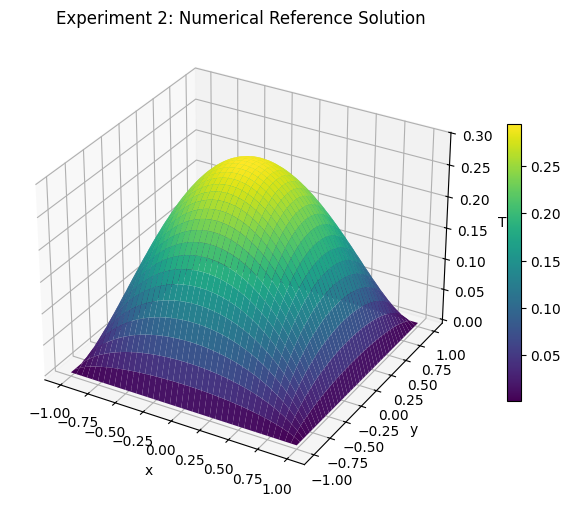

In [ ]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X_fd,
    Y_fd,
    T_fd,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("T")

ax.set_title(
    "Experiment 2: Numerical Reference Solution"
)

fig.colorbar(
    surface,
    shrink=0.6
)

plt.show()

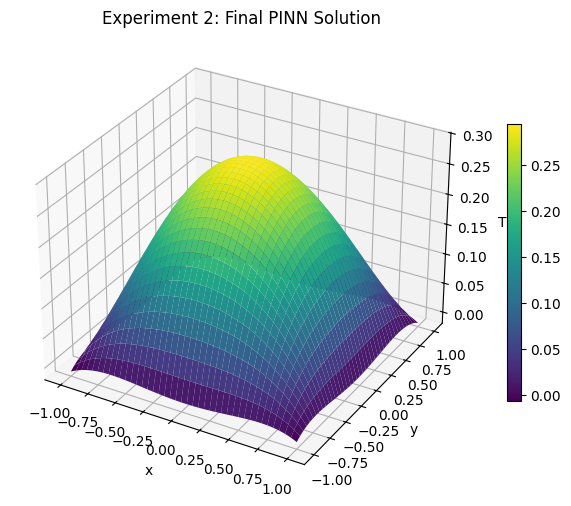

In [ ]:
fig = plt.figure(figsize=(9, 6))

ax = fig.add_subplot(
    111,
    projection="3d"
)

surface = ax.plot_surface(
    X_fd,
    Y_fd,
    T_pinn_exp2_final,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("T")

ax.set_title(
    "Experiment 2: Final PINN Solution"
)

fig.colorbar(
    surface,
    shrink=0.6
)

plt.show()

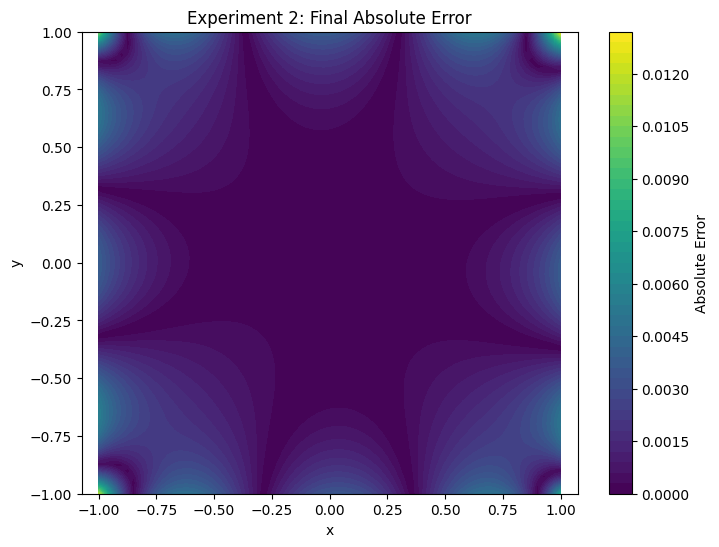

In [ ]:
plt.figure(figsize=(8, 6))

plt.contourf(
    X_fd,
    Y_fd,
    T_error_exp2_final,
    levels=50,
    cmap="viridis"
)

plt.colorbar(
    label="Absolute Error"
)

plt.xlabel("x")
plt.ylabel("y")

plt.title(
    "Experiment 2: Final Absolute Error"
)

plt.axis("equal")

plt.show()

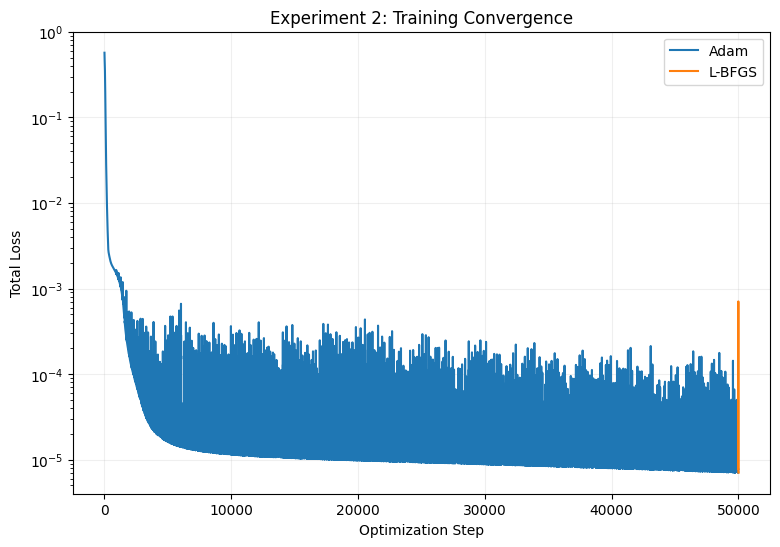

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    np.arange(
        len(loss_history_exp2)
    ),
    loss_history_exp2,
    label="Adam"
)

lbfgs_x = (
    len(loss_history_exp2)
    +
    np.arange(
        len(loss_history_lbfgs_exp2)
    )
)

plt.semilogy(
    lbfgs_x,
    loss_history_lbfgs_exp2,
    label="L-BFGS"
)

plt.xlabel("Optimization Step")
plt.ylabel("Total Loss")

plt.title(
    "Experiment 2: Training Convergence"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Experiment 2 Summary

A Physics-Informed Neural Network was used to solve the two-dimensional
steady-state heat-conduction problem governed by Poisson's equation.

The PINN was trained using:

- 1500 interior residual points,
- 500 boundary points,
- four hidden layers with 50 neurons each,
- tanh activation,
- Glorot uniform initialization,
- Adam followed by L-BFGS.

The boundary condition T = 0 was imposed through the loss function,
matching the soft-boundary approach described in the reference paper.

The original paper validated the PINN against a deal.II finite-element
solution.

In this replication, a finite-difference solution of the same Poisson
equation was used as the independent numerical reference.

The final evaluation compares:

- numerical reference solution,
- PINN solution,
- absolute error,
- prediction MSE,
- test PDE residual.

# Experiment 3: Inverse Problem for a Structural Dynamic System

The third experiment reproduces the inverse structural-dynamics
problem presented in Section 4.3 of the reference paper.

The system represents the free vibration of a single-degree-of-freedom
mass with viscous damping.

The governing equation is:

m d²u/dt² + c du/dt + ku = 0

with initial conditions:

u(0) = u₀

du/dt(0) = v₀

where:

- m is the mass,
- c is the damping coefficient,
- k is the stiffness,
- u(t) is the displacement.

Unlike Experiments 1 and 2, the goal is not only to approximate u(t).

The PINN must also identify the unknown physical parameters c and k
from observed displacement measurements.

## Analytical Solution

### FROM PAPER

For the underdamped system, the analytical displacement is:

u(t) =
exp(-ξωₙt)
[
u₀ cos(ωᴅt)
+
(v₀ + ξωₙu₀)/ωᴅ × sin(ωᴅt)
]

where:

ωₙ = sqrt(k/m)

ξ = c / (2mωₙ)

ωᴅ = ωₙ sqrt(1 - ξ²)

The paper assumes an underdamped system:

ξ < 1.

## Experiment 3 Configuration

### FROM PAPER

The authors use:

m = 1

u₀ = 1

v₀ = 1

True damping coefficient:

c = 0.4

True stiffness:

k = 4

Training data:

- 50 equally spaced observation points Γd
- 100 random physics-residual points Γf
- 50 boundary points Γb
- 10,000 test points Γtest

Loss weights:

wf = 1/4

wb = 1/4

wd = 1/4

Neural network:

- 3 hidden layers
- 32 neurons per hidden layer
- no output transformation
- Glorot uniform initialization

Optimization:

- Adam only
- 100,000 epochs
- learning rate = 0.0005

Unlike Experiments 1 and 2, L-BFGS is not used.

In [ ]:
# ============================================================
# EXPERIMENT 3 - PARAMETERS FROM PAPER
# ============================================================

MASS = 1.0

U0 = 1.0
V0 = 1.0

C_TRUE = 0.4
K_TRUE = 4.0

N_DATA_EXP3 = 50
N_F_EXP3 = 100
N_B_EXP3 = 50

N_TEST_EXP3 = 10000

HIDDEN_LAYERS_EXP3 = 3
HIDDEN_NEURONS_EXP3 = 32

LEARNING_RATE_EXP3 = 0.0005
ADAM_EPOCHS_EXP3_PAPER = 100000

W_F_EXP3 = 1 / 4
W_B_EXP3 = 1 / 4
W_D_EXP3 = 1 / 4

print("Experiment 3 configuration loaded.")

Experiment 3 configuration loaded.


### Implementation Detail: Time Domain

The text of the reference paper does not explicitly state the maximum
time used for Experiment 3.

However, Figure 4 displays the displacement response over approximately:

0 ≤ t ≤ 15.

### OUR IMPLEMENTATION CHOICE

We therefore use:

t ∈ [0,15]

for the observations, residual points and final evaluation.

This value is inferred from Figure 4 rather than explicitly specified
in the experiment text.

In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
# Inferred from the time range displayed in Figure 4
# ============================================================

T_MIN_EXP3 = 0.0
T_MAX_EXP3 = 15.0

print(
    "Experiment 3 time interval:",
    T_MIN_EXP3,
    "to",
    T_MAX_EXP3
)

Experiment 3 time interval: 0.0 to 15.0


## Synthetic Observation Generation

### FROM PAPER

The displacement observations are generated using the analytical
solution with the underlying true parameters:

c = 0.4

k = 4

The paper uses 50 equally spaced observation points.

No measurement-noise model is described in the paper.

### OUR IMPLEMENTATION

We therefore generate noiseless analytical observations at 50 equally
spaced time locations over the selected interval [0,15].

In [ ]:
def analytical_solution_exp3(
    t,
    c=C_TRUE,
    k=K_TRUE,
    m=MASS,
    u0=U0,
    v0=V0
):

    omega_n = np.sqrt(k / m)

    xi = c / (
        2 * m * omega_n
    )

    omega_d = (
        omega_n
        *
        np.sqrt(1 - xi**2)
    )

    displacement = (
        np.exp(
            -xi * omega_n * t
        )
        *
        (
            u0
            * np.cos(
                omega_d * t
            )
            +
            (
                v0
                +
                xi
                * omega_n
                * u0
            )
            /
            omega_d
            *
            np.sin(
                omega_d * t
            )
        )
    )

    return displacement

In [ ]:
# ============================================================
# FROM PAPER:
# 50 equally spaced observation points
# ============================================================

t_data_exp3 = np.linspace(
    T_MIN_EXP3,
    T_MAX_EXP3,
    N_DATA_EXP3
).reshape(-1, 1)

u_data_exp3 = analytical_solution_exp3(
    t_data_exp3
)


t_data_tensor_exp3 = torch.tensor(
    t_data_exp3,
    dtype=torch.float32,
    device=device
)

u_data_tensor_exp3 = torch.tensor(
    u_data_exp3,
    dtype=torch.float32,
    device=device
)

print(
    "Observation points:",
    len(t_data_exp3)
)

print("\nFirst five observations:")

for i in range(5):
    print(
        f"t={t_data_exp3[i,0]:.3f}, "
        f"u={u_data_exp3[i,0]:.6f}"
    )

Observation points: 50

First five observations:
t=0.000, u=1.000000
t=0.306, u=1.095968
t=0.612, u=0.806140
t=0.918, u=0.274078
t=1.224, u=-0.290378


## Observation Data

The displacement observations represent a damped oscillatory response.

The PINN will use these measurements together with the governing
differential equation to estimate both the displacement function and
the unknown parameters c and k.

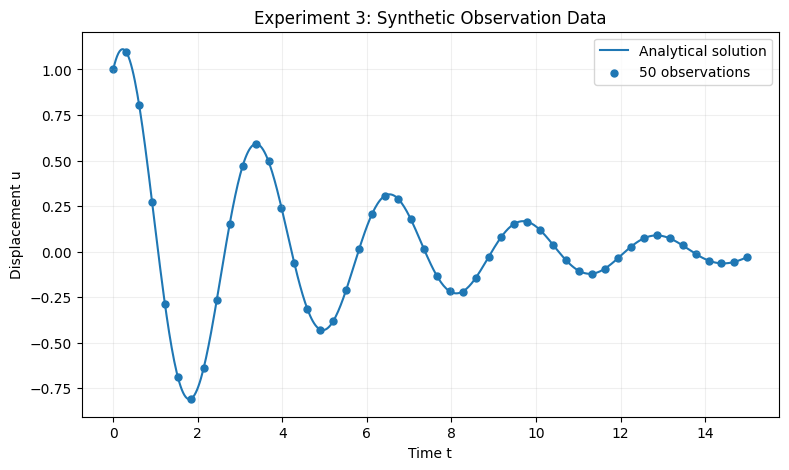

In [ ]:
t_dense_exp3 = np.linspace(
    T_MIN_EXP3,
    T_MAX_EXP3,
    500
).reshape(-1, 1)

u_true_dense_exp3 = analytical_solution_exp3(
    t_dense_exp3
)


plt.figure(figsize=(9, 5))

plt.plot(
    t_dense_exp3,
    u_true_dense_exp3,
    label="Analytical solution"
)

plt.scatter(
    t_data_exp3,
    u_data_exp3,
    s=25,
    label="50 observations"
)

plt.xlabel("Time t")
plt.ylabel("Displacement u")

plt.title(
    "Experiment 3: Synthetic Observation Data"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Physics Residual Points

### FROM PAPER

The authors use 100 randomly sampled points to form Γf.

At these locations, the PINN is constrained by the differential
equation:

m u_tt + c u_t + ku = 0.

In [ ]:
# ============================================================
# 100 random PDE residual points
# ============================================================

t_f_exp3 = (
    T_MIN_EXP3
    +
    (
        T_MAX_EXP3
        - T_MIN_EXP3
    )
    *
    torch.rand(
        N_F_EXP3,
        1,
        device=device
    )
)

t_f_exp3.requires_grad_(True)

print(
    "Physics residual points:",
    t_f_exp3.shape[0]
)

print(
    "Leaf tensor:",
    t_f_exp3.is_leaf
)

Physics residual points: 100
Leaf tensor: True


### Implementation Detail: Boundary Points

The reference paper states that 50 random points are used to form Γb.

However, for this one-dimensional time-dependent system, the reported
physical conditions are the two initial conditions:

u(0) = 1

u_t(0) = 1.

The paper does not explain how the 50 Γb points are constructed from
these two conditions.

### OUR IMPLEMENTATION CHOICE

We evaluate both initial-condition residuals at t = 0.

The two initial residuals are included in the boundary loss Lb.

The reported value N_b = 50 is retained as paper metadata, but repeated
copies of the identical point t = 0 would not add new information, so
the two unique initial-condition constraints are evaluated directly.

## PINN Architecture

### FROM PAPER

Experiment 3 uses:

Input:

t

3 hidden layers

32 neurons per hidden layer

Glorot uniform initialization

No transformation of the network output.

The network predicts:

u(t).

In addition to the neural-network weights, the physical parameters c
and k are optimized during training.

In [ ]:
class StructuralDynamicsPINN(nn.Module):

    def __init__(self):
        super().__init__()

        layers = []

        # Input t -> 32
        layers.append(
            nn.Linear(
                1,
                HIDDEN_NEURONS_EXP3
            )
        )

        layers.append(nn.Tanh())

        # Remaining hidden layers
        for _ in range(
            HIDDEN_LAYERS_EXP3 - 1
        ):

            layers.append(
                nn.Linear(
                    HIDDEN_NEURONS_EXP3,
                    HIDDEN_NEURONS_EXP3
                )
            )

            layers.append(nn.Tanh())

        # Linear output u(t)
        layers.append(
            nn.Linear(
                HIDDEN_NEURONS_EXP3,
                1
            )
        )

        self.network = nn.Sequential(
            *layers
        )

        # FROM PAPER:
        # Glorot uniform initialization

        for layer in self.network:

            if isinstance(
                layer,
                nn.Linear
            ):

                nn.init.xavier_uniform_(
                    layer.weight
                )

                nn.init.zeros_(
                    layer.bias
                )


    def forward(self, t):

        return self.network(t)

## Trainable Physical Parameters

The objective of the inverse problem is to recover:

c

and

k.

The paper gives the true values used to generate the observations:

c = 0.4

k = 4.

However, the PINN is not provided with these values during training.

### OUR IMPLEMENTATION CHOICE

The paper does not report the initial guesses used for c and k.

We initialize:

c = 1.0

k = 1.0

and optimize them together with the neural-network parameters.

In [ ]:
model3 = StructuralDynamicsPINN().to(
    device
)


# ============================================================
# OUR IMPLEMENTATION CHOICE
# Initial parameter guesses
# ============================================================

c_est = nn.Parameter(
    torch.tensor(
        1.0,
        dtype=torch.float32,
        device=device
    )
)

k_est = nn.Parameter(
    torch.tensor(
        1.0,
        dtype=torch.float32,
        device=device
    )
)


optimizer_exp3 = optim.Adam(
    list(
        model3.parameters()
    )
    +
    [
        c_est,
        k_est
    ],
    lr=LEARNING_RATE_EXP3
)


print(model3)

print(
    "\nInitial c estimate:",
    c_est.item()
)

print(
    "Initial k estimate:",
    k_est.item()
)

StructuralDynamicsPINN(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)

Initial c estimate: 1.0
Initial k estimate: 1.0


## Physics Residual

With m = 1, the governing equation becomes:

u_tt + c u_t + ku = 0.

The PINN output u(t) is differentiated using automatic differentiation.

The physics residual is therefore:

f(t) = u_tt + c u_t + ku.

The physics loss Lf is the mean squared value of this residual at the
100 collocation points.

In [ ]:
def experiment3_pde_residual(
    model,
    t,
    c,
    k
):

    u = model(t)

    u_t = derivative(
        u,
        t
    )

    u_tt = derivative(
        u_t,
        t
    )

    residual = (
        MASS * u_tt
        +
        c * u_t
        +
        k * u
    )

    return residual

## Experiment 3 Loss Function

### FROM PAPER

The loss weights are:

wf = 1/4

wb = 1/4

wd = 1/4

The total loss is:

L = wf Lf + wb Lb + wd Ld

where:

Lf = physics-equation residual loss

Lb = initial/boundary-condition loss

Ld = observed-displacement data loss.

For this system, the initial conditions are:

u(0) = 1

u_t(0) = 1.

In [ ]:
def loss_experiment3(
    model,
    c,
    k
):

    # ========================================================
    # PHYSICS LOSS
    # ========================================================

    residual_f = experiment3_pde_residual(
        model,
        t_f_exp3,
        c,
        k
    )

    loss_f = torch.mean(
        residual_f ** 2
    )


    # ========================================================
    # DATA LOSS
    # ========================================================

    u_pred_data = model(
        t_data_tensor_exp3
    )

    loss_d = torch.mean(
        (
            u_pred_data
            -
            u_data_tensor_exp3
        ) ** 2
    )


    # ========================================================
    # INITIAL / BOUNDARY LOSS
    # ========================================================

    t0 = torch.zeros(
        1,
        1,
        dtype=torch.float32,
        device=device,
        requires_grad=True
    )

    u0_pred = model(t0)

    u0_t_pred = derivative(
        u0_pred,
        t0
    )


    residual_u0 = (
        u0_pred - U0
    )

    residual_v0 = (
        u0_t_pred - V0
    )


    loss_b = (
        torch.mean(
            residual_u0 ** 2
        )
        +
        torch.mean(
            residual_v0 ** 2
        )
    ) / 2


    # ========================================================
    # TOTAL LOSS - FROM PAPER
    # ========================================================

    total_loss = (
        W_F_EXP3 * loss_f
        +
        W_B_EXP3 * loss_b
        +
        W_D_EXP3 * loss_d
    )


    return (
        total_loss,
        loss_f,
        loss_b,
        loss_d
    )

## Initial Loss Check

Before training, the complete inverse-problem loss is evaluated once.

The calculation should produce finite values for:

- total loss,
- physics loss,
- initial-condition loss,
- data loss.

In [ ]:
initial_total_exp3, \
initial_physics_exp3, \
initial_boundary_exp3, \
initial_data_exp3 = loss_experiment3(
    model3,
    c_est,
    k_est
)


print(
    "Initial total loss   :",
    initial_total_exp3.item()
)

print(
    "Initial physics loss :",
    initial_physics_exp3.item()
)

print(
    "Initial boundary loss:",
    initial_boundary_exp3.item()
)

print(
    "Initial data loss    :",
    initial_data_exp3.item()
)

Initial total loss   : 1.2640457153320312
Initial physics loss : 1.6764408349990845
Initial boundary loss: 1.629004716873169
Initial data loss    : 1.7507373094558716


## Development Training

### FROM PAPER

The final experiment uses:

Adam only

100,000 epochs

learning rate = 0.0005.

### Development Run

A shorter run is first performed to confirm that:

- the overall loss decreases,
- c moves toward 0.4,
- k moves toward 4.

Once this behavior is confirmed, the model will be reinitialized and
trained using the full paper configuration.

In [ ]:
QUICK_RUN_EXP3 = True

if QUICK_RUN_EXP3:

    ADAM_EPOCHS_EXP3 = 5000

else:

    ADAM_EPOCHS_EXP3 = \
        ADAM_EPOCHS_EXP3_PAPER


print(
    "Experiment 3 Adam epochs:",
    ADAM_EPOCHS_EXP3
)

Experiment 3 Adam epochs: 5000


In [ ]:
loss_history_exp3 = []

physics_history_exp3 = []
boundary_history_exp3 = []
data_history_exp3 = []

c_history_exp3 = []
k_history_exp3 = []


print(
    "Starting Experiment 3 Adam training..."
)

print("-" * 75)


for epoch in range(
    ADAM_EPOCHS_EXP3
):

    optimizer_exp3.zero_grad()

    total_loss, \
    loss_f, \
    loss_b, \
    loss_d = loss_experiment3(
        model3,
        c_est,
        k_est
    )

    total_loss.backward()

    optimizer_exp3.step()


    # Save losses

    loss_history_exp3.append(
        total_loss.item()
    )

    physics_history_exp3.append(
        loss_f.item()
    )

    boundary_history_exp3.append(
        loss_b.item()
    )

    data_history_exp3.append(
        loss_d.item()
    )


    # Save physical parameters

    c_history_exp3.append(
        c_est.item()
    )

    k_history_exp3.append(
        k_est.item()
    )


    if (
        epoch == 0
        or (epoch + 1) % 500 == 0
    ):

        print(
            f"Epoch {epoch+1:6d} | "
            f"Loss={total_loss.item():.6e} | "
            f"c={c_est.item():.6f} | "
            f"k={k_est.item():.6f}"
        )


print("-" * 75)

print(
    "Experiment 3 quick training complete."
)

Starting Experiment 3 Adam training...
---------------------------------------------------------------------------
Epoch      1 | Loss=1.264046e+00 | c=0.999500 | k=0.999500
Epoch    500 | Loss=4.511302e-02 | c=1.143672 | k=0.982594
Epoch   1000 | Loss=4.202005e-02 | c=1.278152 | k=1.054882
Epoch   1500 | Loss=3.848664e-02 | c=1.346893 | k=1.164635
Epoch   2000 | Loss=1.753500e-02 | c=1.418783 | k=1.232457
Epoch   2500 | Loss=1.629768e-02 | c=1.554776 | k=1.249444
Epoch   3000 | Loss=1.593342e-02 | c=1.591728 | k=1.282575
Epoch   3500 | Loss=1.565216e-02 | c=1.572992 | k=1.331574
Epoch   4000 | Loss=1.531791e-02 | c=1.515998 | k=1.399993
Epoch   4500 | Loss=1.490841e-02 | c=1.435335 | k=1.493672
Epoch   5000 | Loss=1.435163e-02 | c=1.343128 | k=1.618227
---------------------------------------------------------------------------
Experiment 3 quick training complete.


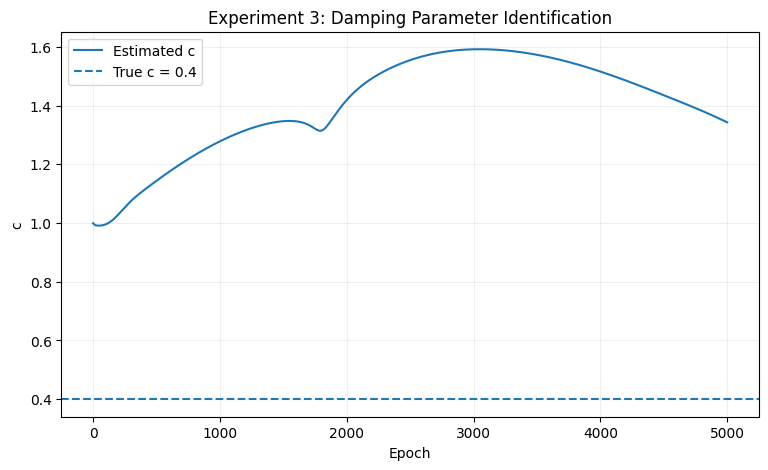

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    c_history_exp3,
    label="Estimated c"
)

plt.axhline(
    C_TRUE,
    linestyle="--",
    label="True c = 0.4"
)

plt.xlabel("Epoch")
plt.ylabel("c")

plt.title(
    "Experiment 3: Damping Parameter Identification"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

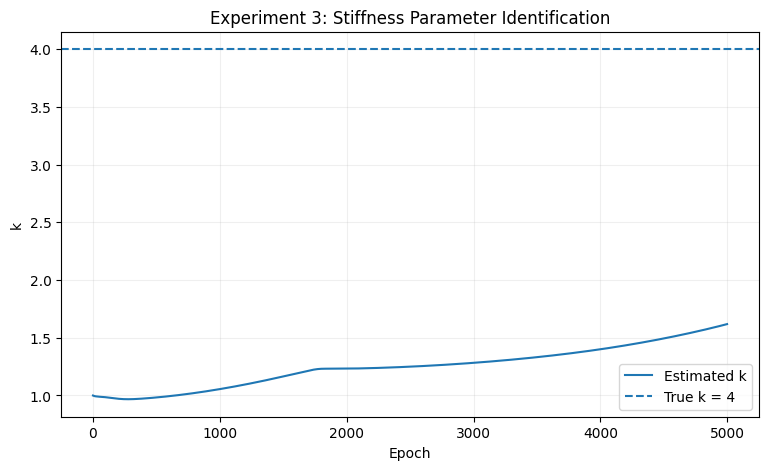

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_history_exp3,
    label="Estimated k"
)

plt.axhline(
    K_TRUE,
    linestyle="--",
    label="True k = 4"
)

plt.xlabel("Epoch")
plt.ylabel("k")

plt.title(
    "Experiment 3: Stiffness Parameter Identification"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

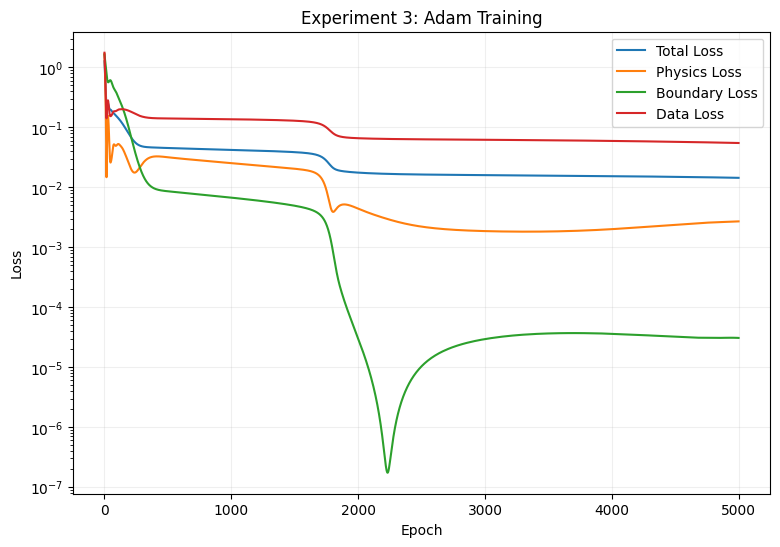

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    loss_history_exp3,
    label="Total Loss"
)

plt.semilogy(
    physics_history_exp3,
    label="Physics Loss"
)

plt.semilogy(
    boundary_history_exp3,
    label="Boundary Loss"
)

plt.semilogy(
    data_history_exp3,
    label="Data Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Experiment 3: Adam Training"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

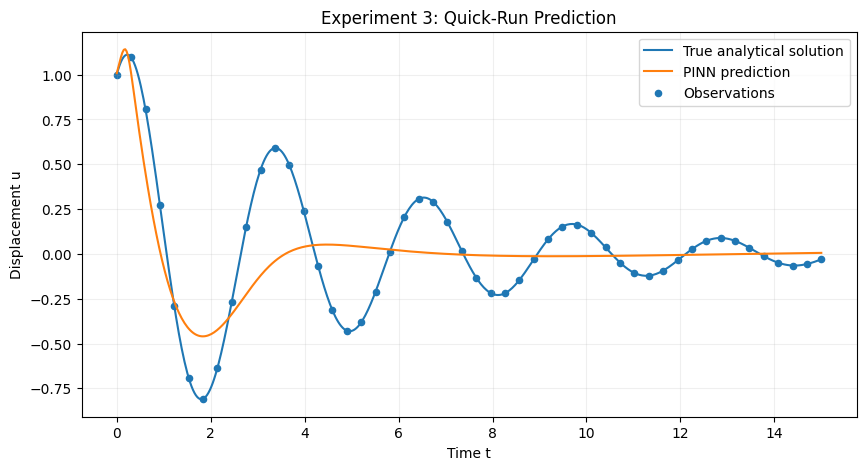

In [ ]:
t_dense_tensor_exp3 = torch.tensor(
    t_dense_exp3,
    dtype=torch.float32,
    device=device
)


with torch.no_grad():

    u_pred_quick_exp3 = model3(
        t_dense_tensor_exp3
    ).cpu().numpy()


plt.figure(figsize=(10, 5))

plt.plot(
    t_dense_exp3,
    u_true_dense_exp3,
    label="True analytical solution"
)

plt.plot(
    t_dense_exp3,
    u_pred_quick_exp3,
    label="PINN prediction"
)

plt.scatter(
    t_data_exp3,
    u_data_exp3,
    s=20,
    label="Observations"
)

plt.xlabel("Time t")
plt.ylabel("Displacement u")

plt.title(
    "Experiment 3: Quick-Run Prediction"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Extended Development Run to 20,000 Epochs

The initial 5,000-epoch development run did not yet recover the true
physical parameters.

Since the reference paper trains Experiment 3 for 100,000 Adam epochs,
the same current model is continued for another 15,000 epochs to reach
20,000 total epochs.

This is still a development check and not the final paper run.

In [ ]:
# ============================================================
# EXPERIMENT 3 - CONTINUE FROM 5,000 TO 20,000 TOTAL EPOCHS
#
# IMPORTANT:
# Continue the SAME:
# model3
# c_est
# k_est
# optimizer_exp3
# ============================================================

EXTRA_EPOCHS = 15000

for epoch in range(EXTRA_EPOCHS):

    optimizer_exp3.zero_grad()

    total_loss, loss_f, loss_b, loss_d = loss_experiment3(
        model3,
        c_est,
        k_est
    )

    total_loss.backward()
    optimizer_exp3.step()

    # Save histories
    loss_history_exp3.append(total_loss.item())
    physics_history_exp3.append(loss_f.item())
    boundary_history_exp3.append(loss_b.item())
    data_history_exp3.append(loss_d.item())

    c_history_exp3.append(c_est.item())
    k_history_exp3.append(k_est.item())

    total_epoch = 5000 + epoch + 1

    if total_epoch % 2500 == 0:

        print(
            f"Epoch {total_epoch:6d} | "
            f"Loss={total_loss.item():.6e} | "
            f"c={c_est.item():.6f} | "
            f"k={k_est.item():.6f} | "
            f"Data={loss_d.item():.6e}"
        )

Epoch   7500 | Loss=1.027751e-02 | c=1.042737 | k=2.533495 | Data=3.772129e-02
Epoch  10000 | Loss=7.838652e-03 | c=1.225260 | k=3.390601 | Data=2.775853e-02
Epoch  12500 | Loss=7.061145e-03 | c=1.343063 | k=3.898234 | Data=2.498420e-02
Epoch  15000 | Loss=6.673804e-03 | c=1.310486 | k=3.954475 | Data=2.357104e-02
Epoch  17500 | Loss=5.703931e-03 | c=1.127206 | k=4.021523 | Data=1.953181e-02
Epoch  20000 | Loss=4.518513e-03 | c=0.919030 | k=4.055698 | Data=1.421399e-02


## Parameter Estimates After 20,000 Epochs

The following plots show the complete parameter trajectories from
Epoch 1 to Epoch 20,000.

The true parameters used to generate the observations are:

c = 0.4

k = 4.0

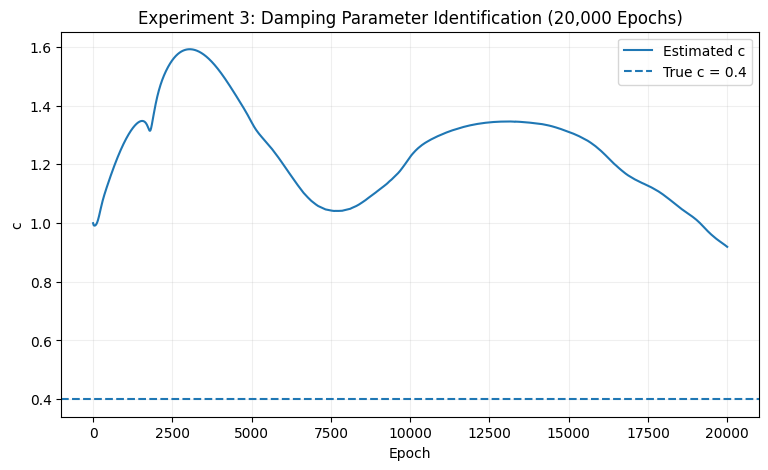

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    c_history_exp3,
    label="Estimated c"
)

plt.axhline(
    C_TRUE,
    linestyle="--",
    label="True c = 0.4"
)

plt.xlabel("Epoch")
plt.ylabel("c")

plt.title(
    "Experiment 3: Damping Parameter Identification "
    "(20,000 Epochs)"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

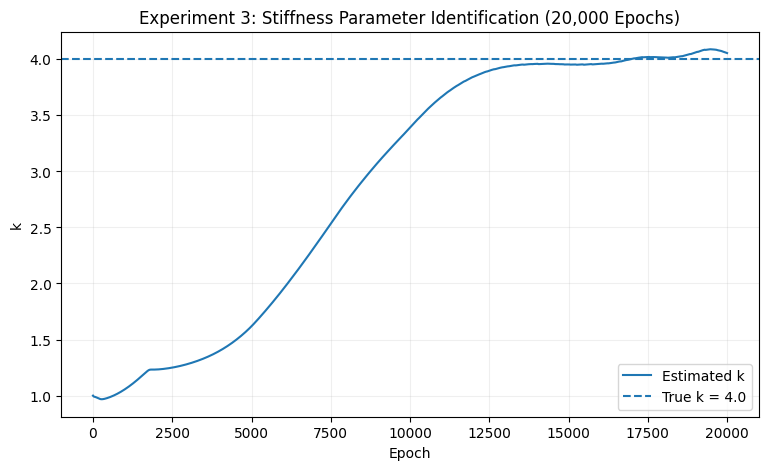

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_history_exp3,
    label="Estimated k"
)

plt.axhline(
    K_TRUE,
    linestyle="--",
    label="True k = 4.0"
)

plt.xlabel("Epoch")
plt.ylabel("k")

plt.title(
    "Experiment 3: Stiffness Parameter Identification "
    "(20,000 Epochs)"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

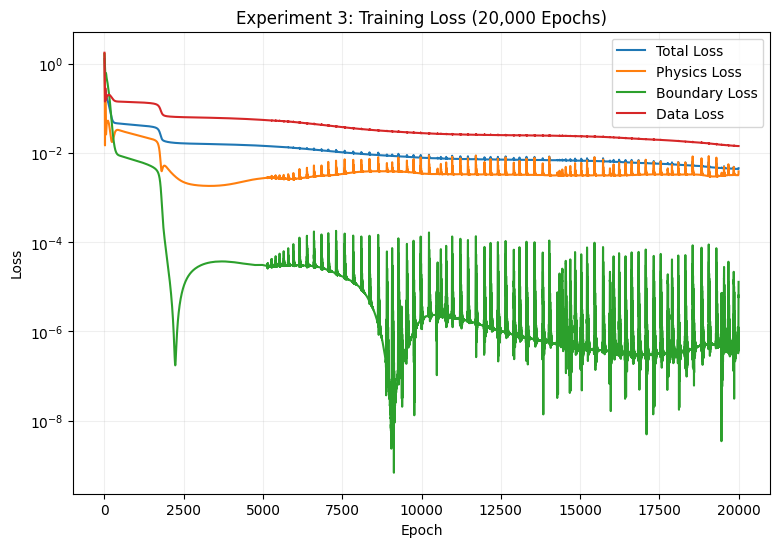

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    loss_history_exp3,
    label="Total Loss"
)

plt.semilogy(
    physics_history_exp3,
    label="Physics Loss"
)

plt.semilogy(
    boundary_history_exp3,
    label="Boundary Loss"
)

plt.semilogy(
    data_history_exp3,
    label="Data Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Experiment 3: Training Loss "
    "(20,000 Epochs)"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

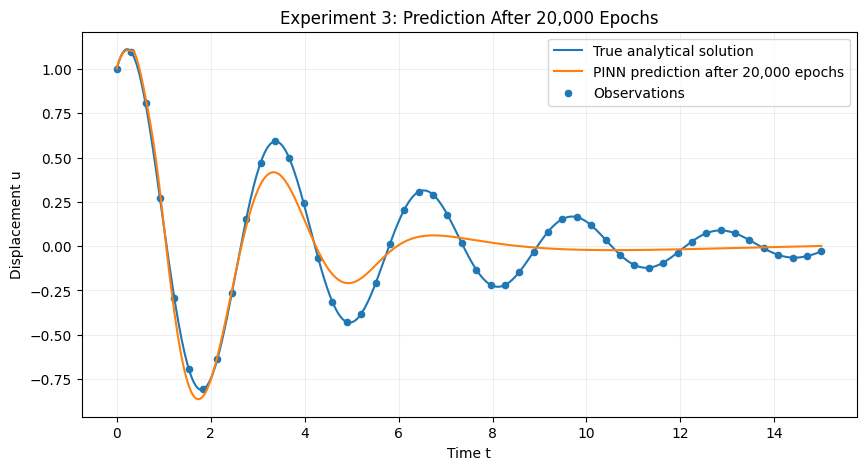

In [ ]:
with torch.no_grad():

    u_pred_20k_exp3 = model3(
        t_dense_tensor_exp3
    ).cpu().numpy()


plt.figure(figsize=(10, 5))

plt.plot(
    t_dense_exp3,
    u_true_dense_exp3,
    label="True analytical solution"
)

plt.plot(
    t_dense_exp3,
    u_pred_20k_exp3,
    label="PINN prediction after 20,000 epochs"
)

plt.scatter(
    t_data_exp3,
    u_data_exp3,
    s=20,
    label="Observations"
)

plt.xlabel("Time t")
plt.ylabel("Displacement u")

plt.title(
    "Experiment 3: Prediction After 20,000 Epochs"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("=" * 55)
print("EXPERIMENT 3: 20,000 EPOCH DEVELOPMENT CHECK")
print("=" * 55)

print(
    f"Estimated c : {c_est.item():.6f}"
)

print(
    f"True c      : {C_TRUE:.6f}"
)

print()

print(
    f"Estimated k : {k_est.item():.6f}"
)

print(
    f"True k      : {K_TRUE:.6f}"
)

print()

print(
    f"Final Loss  : {loss_history_exp3[-1]:.6e}"
)

print(
    f"Data Loss   : {data_history_exp3[-1]:.6e}"
)

print("=" * 55)

EXPERIMENT 3: 20,000 EPOCH DEVELOPMENT CHECK
Estimated c : 0.919030
True c      : 0.400000

Estimated k : 4.055698
True k      : 4.000000

Final Loss  : 4.518513e-03
Data Loss   : 1.421399e-02


## Revised Parameter Initialization

The first development run initialized the unknown physical parameters as:

c = 1.0

k = 1.0

After 20,000 epochs, the estimates had not converged toward the known
values and the predicted displacement did not reproduce the complete
oscillatory response.

The reference paper does not state the exact initial values used for
the trainable parameters c and k.

However, the parameter trajectories shown in Figure 4 appear to begin
approximately around:

c ≈ 0.5

k ≈ 2.0

### OUR IMPLEMENTATION CHOICE

A fresh Experiment 3 model is therefore initialized with:

c = 0.5

k = 2.0

These values are implementation choices inferred approximately from
the published parameter-convergence plot and are not explicitly
reported hyperparameters in the paper.

In [ ]:
# ============================================================
# REVISED EXPERIMENT 3 DEVELOPMENT MODEL
# ============================================================

model3_v2 = StructuralDynamicsPINN().to(device)

print(model3_v2)

StructuralDynamicsPINN(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): Tanh()
    (4): Linear(in_features=32, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [ ]:
# ============================================================
# OUR IMPLEMENTATION CHOICE
#
# Approximate starting values inferred from Figure 4.
# Exact initial values are not reported by the authors.
# ============================================================

c_est_v2 = nn.Parameter(
    torch.tensor(
        0.5,
        dtype=torch.float32,
        device=device
    )
)

k_est_v2 = nn.Parameter(
    torch.tensor(
        2.0,
        dtype=torch.float32,
        device=device
    )
)


optimizer_exp3_v2 = optim.Adam(
    list(model3_v2.parameters())
    +
    [
        c_est_v2,
        k_est_v2
    ],
    lr=LEARNING_RATE_EXP3
)


print(
    "Initial c estimate:",
    c_est_v2.item()
)

print(
    "Initial k estimate:",
    k_est_v2.item()
)

Initial c estimate: 0.5
Initial k estimate: 2.0


In [ ]:
initial_total_v2, \
initial_physics_v2, \
initial_boundary_v2, \
initial_data_v2 = loss_experiment3(
    model3_v2,
    c_est_v2,
    k_est_v2
)


print("Revised initialization loss")
print("-" * 45)

print(
    "Total loss   :",
    initial_total_v2.item()
)

print(
    "Physics loss :",
    initial_physics_v2.item()
)

print(
    "Boundary loss:",
    initial_boundary_v2.item()
)

print(
    "Data loss    :",
    initial_data_v2.item()
)

Revised initialization loss
---------------------------------------------
Total loss   : 0.350588858127594
Physics loss : 0.3181346654891968
Boundary loss: 0.8631560802459717
Data loss    : 0.2210647314786911


## Revised 20,000-Epoch Development Run

A fresh PINN is trained for 20,000 Adam epochs using the revised
parameter initialization.

The purpose of this run is to confirm that:

- c moves toward 0.4,
- k moves toward 4.0,
- the predicted displacement reproduces multiple oscillations.

If this behavior is observed, the same initialization strategy will
be used for the final 100,000-epoch replication.

In [ ]:
DEV_EPOCHS_EXP3_V2 = 20000


loss_history_exp3_v2 = []

physics_history_exp3_v2 = []
boundary_history_exp3_v2 = []
data_history_exp3_v2 = []

c_history_exp3_v2 = []
k_history_exp3_v2 = []


print(
    "Starting revised Experiment 3 development run..."
)

print("-" * 80)


for epoch in range(DEV_EPOCHS_EXP3_V2):

    optimizer_exp3_v2.zero_grad()

    total_loss, \
    loss_f, \
    loss_b, \
    loss_d = loss_experiment3(
        model3_v2,
        c_est_v2,
        k_est_v2
    )

    total_loss.backward()

    optimizer_exp3_v2.step()


    # Store losses
    loss_history_exp3_v2.append(
        total_loss.item()
    )

    physics_history_exp3_v2.append(
        loss_f.item()
    )

    boundary_history_exp3_v2.append(
        loss_b.item()
    )

    data_history_exp3_v2.append(
        loss_d.item()
    )


    # Store parameter estimates
    c_history_exp3_v2.append(
        c_est_v2.item()
    )

    k_history_exp3_v2.append(
        k_est_v2.item()
    )


    if (
        epoch == 0
        or (epoch + 1) % 2500 == 0
    ):

        print(
            f"Epoch {epoch+1:6d} | "
            f"Loss={total_loss.item():.6e} | "
            f"c={c_est_v2.item():.6f} | "
            f"k={k_est_v2.item():.6f} | "
            f"Data={loss_d.item():.6e}"
        )


print("-" * 80)

print(
    "Revised 20,000-epoch development run complete."
)

Starting revised Experiment 3 development run...
--------------------------------------------------------------------------------
Epoch      1 | Loss=3.505889e-01 | c=0.499500 | k=1.999500 | Data=2.210647e-01
Epoch   2500 | Loss=1.203085e-02 | c=1.182683 | k=2.289695 | Data=4.511607e-02
Epoch   5000 | Loss=8.962763e-03 | c=1.001458 | k=3.081056 | Data=3.177708e-02
Epoch   7500 | Loss=4.765355e-03 | c=0.787953 | k=3.731895 | Data=1.586653e-02
Epoch  10000 | Loss=3.441079e-03 | c=0.665814 | k=3.897959 | Data=1.023117e-02
Epoch  12500 | Loss=2.766884e-03 | c=0.614724 | k=3.912808 | Data=8.092187e-03
Epoch  15000 | Loss=2.357979e-03 | c=0.572831 | k=3.880037 | Data=6.610023e-03
Epoch  17500 | Loss=1.668438e-03 | c=0.533603 | k=3.885605 | Data=4.693859e-03
Epoch  20000 | Loss=8.931840e-04 | c=0.476991 | k=3.951508 | Data=2.088152e-03
--------------------------------------------------------------------------------
Revised 20,000-epoch development run complete.


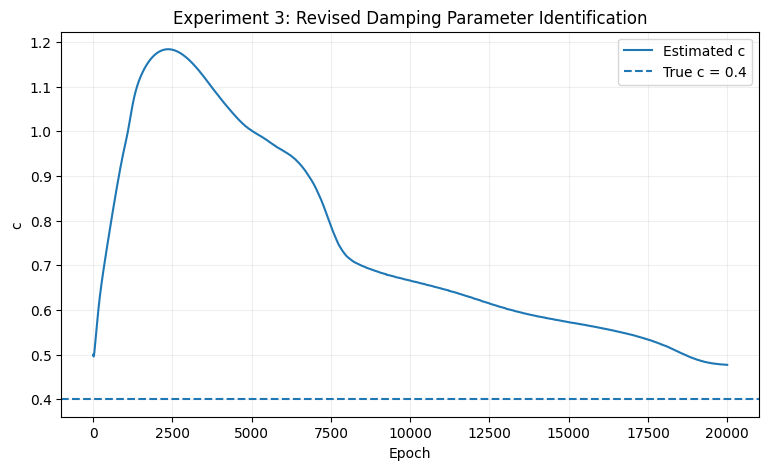

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    c_history_exp3_v2,
    label="Estimated c"
)

plt.axhline(
    C_TRUE,
    linestyle="--",
    label="True c = 0.4"
)

plt.xlabel("Epoch")
plt.ylabel("c")

plt.title(
    "Experiment 3: Revised Damping Parameter Identification"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

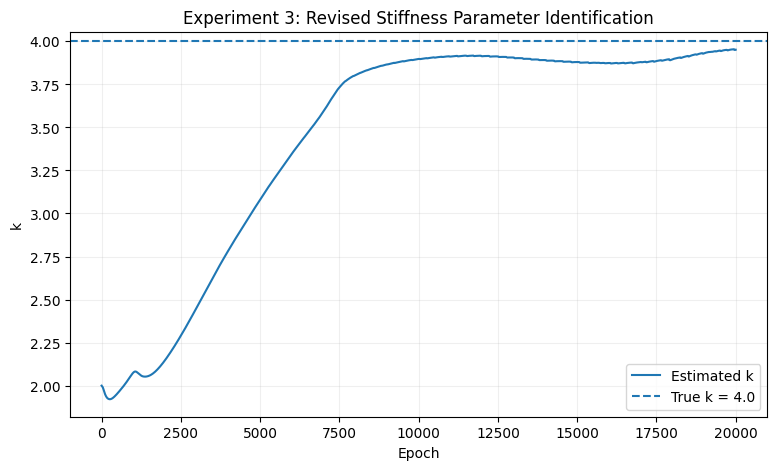

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_history_exp3_v2,
    label="Estimated k"
)

plt.axhline(
    K_TRUE,
    linestyle="--",
    label="True k = 4.0"
)

plt.xlabel("Epoch")
plt.ylabel("k")

plt.title(
    "Experiment 3: Revised Stiffness Parameter Identification"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

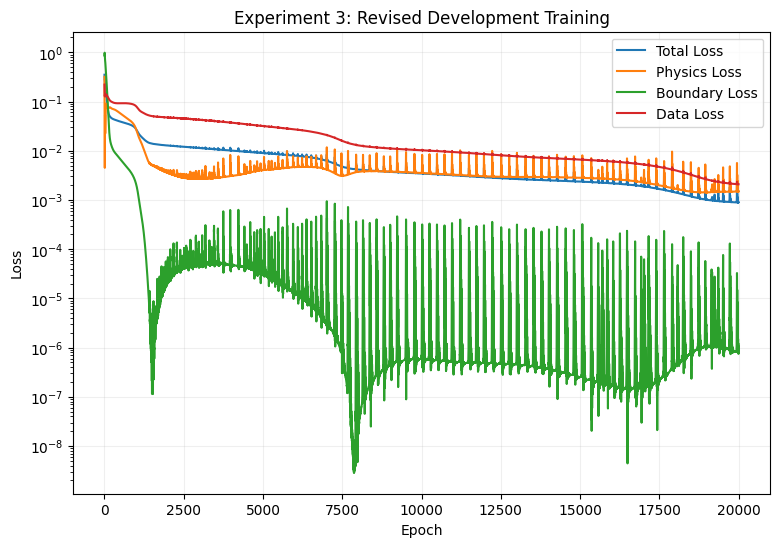

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    loss_history_exp3_v2,
    label="Total Loss"
)

plt.semilogy(
    physics_history_exp3_v2,
    label="Physics Loss"
)

plt.semilogy(
    boundary_history_exp3_v2,
    label="Boundary Loss"
)

plt.semilogy(
    data_history_exp3_v2,
    label="Data Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Experiment 3: Revised Development Training"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

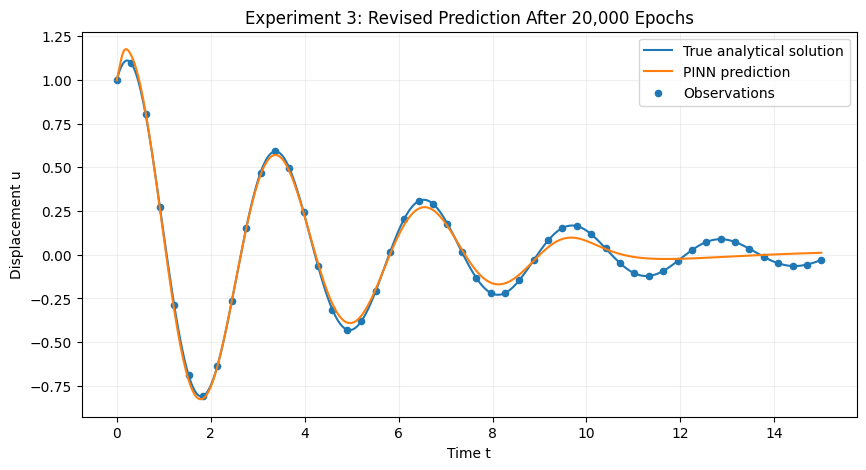

In [ ]:
with torch.no_grad():

    u_pred_v2 = model3_v2(
        t_dense_tensor_exp3
    ).cpu().numpy()


plt.figure(figsize=(10, 5))

plt.plot(
    t_dense_exp3,
    u_true_dense_exp3,
    label="True analytical solution"
)

plt.plot(
    t_dense_exp3,
    u_pred_v2,
    label="PINN prediction"
)

plt.scatter(
    t_data_exp3,
    u_data_exp3,
    s=20,
    label="Observations"
)

plt.xlabel("Time t")
plt.ylabel("Displacement u")

plt.title(
    "Experiment 3: Revised Prediction After 20,000 Epochs"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

In [ ]:
print("=" * 60)
print("EXPERIMENT 3: REVISED 20,000-EPOCH CHECK")
print("=" * 60)

print(
    f"Estimated c : {c_est_v2.item():.6f}"
)

print(
    f"True c      : {C_TRUE:.6f}"
)

print()

print(
    f"Estimated k : {k_est_v2.item():.6f}"
)

print(
    f"True k      : {K_TRUE:.6f}"
)

print()

print(
    f"Final Loss  : "
    f"{loss_history_exp3_v2[-1]:.6e}"
)

print(
    f"Data Loss   : "
    f"{data_history_exp3_v2[-1]:.6e}"
)

print("=" * 60)

EXPERIMENT 3: REVISED 20,000-EPOCH CHECK
Estimated c : 0.476991
True c      : 0.400000

Estimated k : 3.951508
True k      : 4.000000

Final Loss  : 8.931840e-04
Data Loss   : 2.088152e-03


# Final Experiment 3 Training

The revised development run showed successful parameter convergence.

After 20,000 epochs:

- the stiffness estimate k was close to its true value of 4,
- the damping estimate c was moving toward its true value of 0.4,
- the PINN reproduced the damped oscillatory response substantially
  better than the original development run.

### FROM PAPER

Experiment 3 is trained using:

- Adam only
- learning rate = 0.0005
- 100,000 total epochs

### FINAL RUN

The revised model has already completed 20,000 epochs.

It is therefore continued for another 80,000 epochs to obtain exactly
100,000 total Adam training epochs.

In [ ]:
# ============================================================
# FINAL EXPERIMENT 3 TRAINING
#
# Current model3_v2 has already completed 20,000 epochs.
# Continue for another 80,000 -> 100,000 total.
# ============================================================

EXTRA_FINAL_EPOCHS = 80000
START_EPOCH = 20000


print("Continuing Experiment 3 to 100,000 total epochs...")
print("-" * 80)


for epoch in range(EXTRA_FINAL_EPOCHS):

    optimizer_exp3_v2.zero_grad()

    total_loss, \
    loss_f, \
    loss_b, \
    loss_d = loss_experiment3(
        model3_v2,
        c_est_v2,
        k_est_v2
    )

    total_loss.backward()

    optimizer_exp3_v2.step()


    # Store loss history
    loss_history_exp3_v2.append(
        total_loss.item()
    )

    physics_history_exp3_v2.append(
        loss_f.item()
    )

    boundary_history_exp3_v2.append(
        loss_b.item()
    )

    data_history_exp3_v2.append(
        loss_d.item()
    )


    # Store parameter history
    c_history_exp3_v2.append(
        c_est_v2.item()
    )

    k_history_exp3_v2.append(
        k_est_v2.item()
    )


    total_epoch = START_EPOCH + epoch + 1


    if total_epoch % 5000 == 0:

        print(
            f"Epoch {total_epoch:6d} | "
            f"Loss={total_loss.item():.6e} | "
            f"c={c_est_v2.item():.6f} | "
            f"k={k_est_v2.item():.6f} | "
            f"Data={loss_d.item():.6e}"
        )


print("-" * 80)
print("Experiment 3 reached 100,000 total epochs.")

Continuing Experiment 3 to 100,000 total epochs...
--------------------------------------------------------------------------------
Epoch  25000 | Loss=4.895167e-04 | c=0.459757 | k=3.999349 | Data=1.200860e-03
Epoch  30000 | Loss=3.738412e-04 | c=0.441878 | k=4.005803 | Data=7.356949e-04
Epoch  35000 | Loss=3.575122e-04 | c=0.439465 | k=4.000030 | Data=6.641541e-04
Epoch  40000 | Loss=3.429801e-04 | c=0.438655 | k=3.995230 | Data=6.237546e-04
Epoch  45000 | Loss=3.350682e-04 | c=0.437298 | k=3.981612 | Data=5.792124e-04
Epoch  50000 | Loss=1.897151e-04 | c=0.426833 | k=3.982073 | Data=2.907429e-04
Epoch  55000 | Loss=1.212108e-04 | c=0.422580 | k=3.997797 | Data=1.906235e-04
Epoch  60000 | Loss=7.961875e-05 | c=0.418906 | k=4.001857 | Data=1.200734e-04
Epoch  65000 | Loss=5.083636e-05 | c=0.413992 | k=3.996264 | Data=5.172371e-05
Epoch  70000 | Loss=1.403785e-05 | c=0.408537 | k=3.995205 | Data=1.360778e-05
Epoch  75000 | Loss=7.999974e-06 | c=0.405530 | k=3.994390 | Data=5.479728e-06

## Final Parameter Identification Results

The final learned values of c and k are compared with:

True values used to generate the observations:

c = 0.4

k = 4.0

The reference paper reports:

c = 0.40125215

k = 3.9933197

The values obtained in our replication may differ slightly because
several implementation details, including parameter initialization and
random sampling locations, are not fully specified by the paper.

In [ ]:
c_final_exp3 = c_est_v2.item()
k_final_exp3 = k_est_v2.item()

c_error_percent = (
    abs(c_final_exp3 - C_TRUE)
    / C_TRUE
    * 100
)

k_error_percent = (
    abs(k_final_exp3 - K_TRUE)
    / K_TRUE
    * 100
)


print("=" * 60)
print("EXPERIMENT 3 FINAL PARAMETER RESULTS")
print("=" * 60)

print(f"True c            : {C_TRUE:.8f}")
print(f"Estimated c       : {c_final_exp3:.8f}")
print(f"c percentage error: {c_error_percent:.4f}%")

print()

print(f"True k            : {K_TRUE:.8f}")
print(f"Estimated k       : {k_final_exp3:.8f}")
print(f"k percentage error: {k_error_percent:.4f}%")

print()

print("Paper reported:")
print("c = 0.40125215")
print("k = 3.99331970")

print("=" * 60)

EXPERIMENT 3 FINAL PARAMETER RESULTS
True c            : 0.40000000
Estimated c       : 0.40081567
c percentage error: 0.2039%

True k            : 4.00000000
Estimated k       : 3.99529862
k percentage error: 0.1175%

Paper reported:
c = 0.40125215
k = 3.99331970


In [ ]:
with torch.no_grad():

    u_pred_final_exp3 = model3_v2(
        t_dense_tensor_exp3
    ).cpu().numpy()


prediction_mse_exp3 = np.mean(
    (
        u_pred_final_exp3
        - u_true_dense_exp3
    ) ** 2
)


print(
    f"Displacement prediction MSE: "
    f"{prediction_mse_exp3:.6e}"
)

Displacement prediction MSE: 1.234662e-06


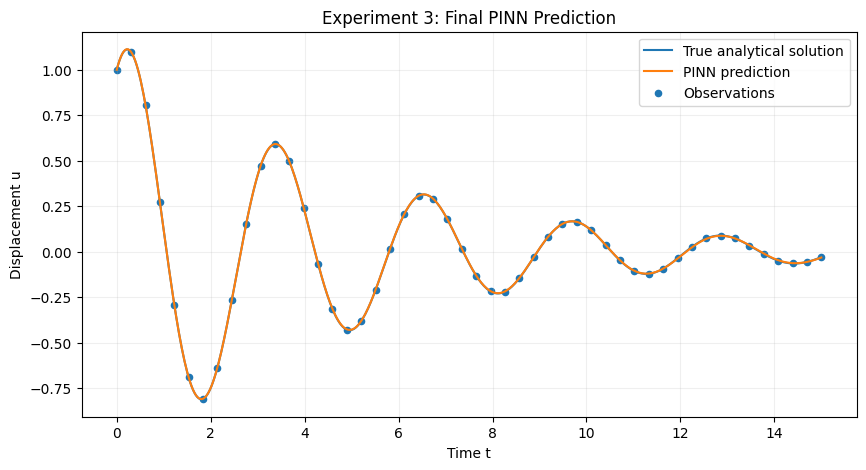

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    t_dense_exp3,
    u_true_dense_exp3,
    label="True analytical solution"
)

plt.plot(
    t_dense_exp3,
    u_pred_final_exp3,
    label="PINN prediction"
)

plt.scatter(
    t_data_exp3,
    u_data_exp3,
    s=20,
    label="Observations"
)

plt.xlabel("Time t")
plt.ylabel("Displacement u")

plt.title(
    "Experiment 3: Final PINN Prediction"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

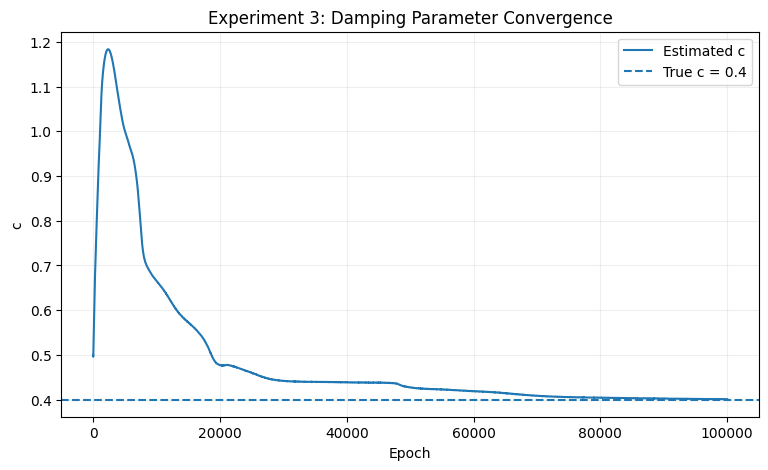

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    c_history_exp3_v2,
    label="Estimated c"
)

plt.axhline(
    C_TRUE,
    linestyle="--",
    label="True c = 0.4"
)

plt.xlabel("Epoch")
plt.ylabel("c")

plt.title(
    "Experiment 3: Damping Parameter Convergence"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

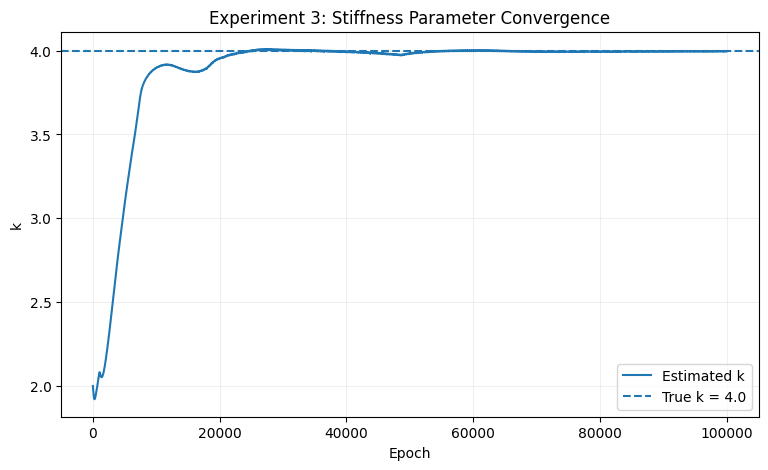

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(
    k_history_exp3_v2,
    label="Estimated k"
)

plt.axhline(
    K_TRUE,
    linestyle="--",
    label="True k = 4.0"
)

plt.xlabel("Epoch")
plt.ylabel("k")

plt.title(
    "Experiment 3: Stiffness Parameter Convergence"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

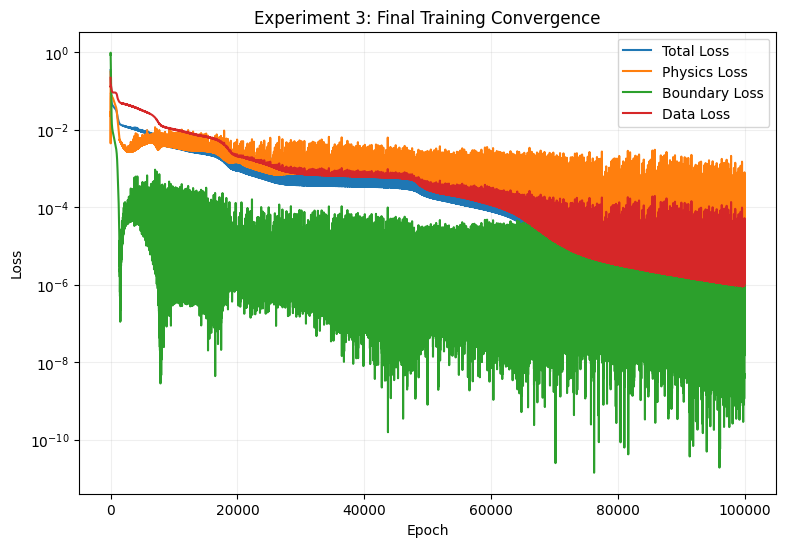

In [ ]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    loss_history_exp3_v2,
    label="Total Loss"
)

plt.semilogy(
    physics_history_exp3_v2,
    label="Physics Loss"
)

plt.semilogy(
    boundary_history_exp3_v2,
    label="Boundary Loss"
)

plt.semilogy(
    data_history_exp3_v2,
    label="Data Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "Experiment 3: Final Training Convergence"
)

plt.legend()
plt.grid(alpha=0.2)

plt.show()

## Experiment 3: Test-Set Evaluation

### FROM PAPER

The paper uses 10,000 test points for Experiment 3.

### OUR IMPLEMENTATION CHOICE

10,000 uniformly random times in [0, 15]. We evaluate the ODE residual
(using the learned c and k) and the displacement MSE against the analytical
solution generated with the true parameters.

In [ ]:
rng_test_exp3 = np.random.default_rng(789)

t_test_exp3 = T_MIN_EXP3 + (T_MAX_EXP3 - T_MIN_EXP3) * rng_test_exp3.random((N_TEST_EXP3, 1))

t_test_tensor_exp3 = torch.tensor(
    t_test_exp3, dtype=torch.float32, device=device, requires_grad=True
)

res_test_exp3 = experiment3_pde_residual(
    model3_v2, t_test_tensor_exp3, c_est_v2, k_est_v2
)
ode_test_loss_exp3 = torch.mean(res_test_exp3 ** 2).item()

with torch.no_grad():
    u_test_pred_exp3 = model3_v2(t_test_tensor_exp3).cpu().numpy()

u_test_true_exp3 = analytical_solution_exp3(t_test_exp3)
mse_test_exp3 = np.mean((u_test_pred_exp3 - u_test_true_exp3) ** 2)

print(f"Experiment 3 test ODE loss        : {ode_test_loss_exp3:.6e}")
print(f"Experiment 3 test displacement MSE: {mse_test_exp3:.6e}")

Experiment 3 test ODE loss        : 2.190669e-04
Experiment 3 test displacement MSE: 1.255806e-06


## Experiment 3 Summary

The inverse structural-dynamics experiment demonstrates the parameter
identification capability of a Physics-Informed Neural Network.

The PINN was trained using:

- 50 equally spaced displacement observations,
- 100 physics residual points,
- the governing structural-dynamics equation,
- the initial displacement and velocity conditions,
- three hidden layers containing 32 neurons each,
- Glorot uniform initialization,
- Adam optimization with learning rate 0.0005,
- 100,000 total training epochs.

The neural-network parameters and the unknown physical parameters c and
k were optimized simultaneously.

The final learned values are compared with the known values:

c = 0.4

k = 4.0

and with the values reported by the reference paper.

No L-BFGS optimization was used for this experiment, matching the
training procedure described by the authors.

# Part C: Extension - Hard Dirichlet Boundary Condition (Experiment 2)

### Motivation

The paper observes that in Experiment 2 the largest errors occur near the
Dirichlet boundary, because T = 0 is only a soft constraint in the loss.
It suggests multiplying the network output by a smooth distance function
d(x) that vanishes on the boundary.

### FROM PAPER (suggested, not implemented by the authors)

T(x, y) = d(x, y) * N(x, y)

### OUR IMPLEMENTATION CHOICE

For the square [-1, 1] x [-1, 1]:

d(x, y) = (1 - x^2)(1 - y^2)

so T = 0 holds exactly on all four edges for any network weights. The
boundary loss is then unnecessary and only the PDE loss is minimized.
All other settings match the soft-BC Experiment 2: 4 hidden layers x 50
neurons, tanh, Glorot uniform, same 1500 collocation points, Adam
(lr = 0.0005, 50,000 epochs), then L-BFGS.

In [ ]:
class HardBCHeatPINN(HeatConductionPINN):

    def forward(self, x, y):

        raw = super().forward(x, y)

        # distance function: zero on all four edges
        return (1 - x ** 2) * (1 - y ** 2) * raw


torch.manual_seed(SEED)

model2_hard = HardBCHeatPINN().to(device)

PART_C_EPOCHS = 50000   # set smaller (e.g. 5000) for a quick test

optimizer_adam_hard = optim.Adam(
    model2_hard.parameters(),
    lr=LEARNING_RATE_EXP2
)


def loss_exp2_hard(model):

    residual = experiment2_pde_residual(
        model,
        x_f_exp2,
        y_f_exp2
    )

    return torch.mean(residual ** 2)


# Verify the hard constraint before training
with torch.no_grad():
    T_edge = model2_hard(x_left_exp2, y_left_exp2)

print("Max |T| on x = -1 edge before training:", T_edge.abs().max().item())

Max |T| on x = -1 edge before training: 0.0


In [ ]:
loss_history_hard = []

print("Starting hard-BC Adam training...")
print("-" * 60)

for epoch in range(PART_C_EPOCHS):

    optimizer_adam_hard.zero_grad()

    loss = loss_exp2_hard(model2_hard)

    loss.backward()

    optimizer_adam_hard.step()

    loss_history_hard.append(loss.item())

    if epoch == 0 or (epoch + 1) % 5000 == 0:
        print(f"Epoch {epoch+1:6d} | PDE loss = {loss.item():.6e}")

print("-" * 60)
print("Hard-BC Adam training complete.")

Starting hard-BC Adam training...
------------------------------------------------------------
Epoch      1 | PDE loss = 4.229389e+00
Epoch   5000 | PDE loss = 3.035121e-03
Epoch  10000 | PDE loss = 7.504795e-04
Epoch  15000 | PDE loss = 1.096636e-04
Epoch  20000 | PDE loss = 3.891434e-04
Epoch  25000 | PDE loss = 6.953541e-05
Epoch  30000 | PDE loss = 1.205197e-05
Epoch  35000 | PDE loss = 2.129119e-05
Epoch  40000 | PDE loss = 2.080779e-05
Epoch  45000 | PDE loss = 8.550849e-06
Epoch  50000 | PDE loss = 2.837626e-06
------------------------------------------------------------
Hard-BC Adam training complete.


In [ ]:
optimizer_lbfgs_hard = torch.optim.LBFGS(
    model2_hard.parameters(),
    lr=1.0,
    max_iter=2000,
    tolerance_grad=1e-9,
    tolerance_change=1e-12,
    history_size=100,
    line_search_fn="strong_wolfe"
)

loss_history_lbfgs_hard = []


def closure_hard():

    optimizer_lbfgs_hard.zero_grad()

    loss = loss_exp2_hard(model2_hard)

    loss.backward()

    loss_history_lbfgs_hard.append(loss.item())

    return loss


optimizer_lbfgs_hard.step(closure_hard)

print("Hard-BC L-BFGS closure evaluations:", len(loss_history_lbfgs_hard))

Hard-BC L-BFGS closure evaluations: 11


In [ ]:
# Evaluate on the same FD grid and the same 10,000 test points as the soft-BC model

with torch.no_grad():
    T_hard = model2_hard(x_grid_exp2, y_grid_exp2).cpu().numpy().reshape(X_fd.shape)

T_error_hard = np.abs(T_fd - T_hard)

mse_exp2_hard = np.mean((T_fd - T_hard) ** 2)
max_error_exp2_hard = np.max(T_error_hard)

res_hard = experiment2_pde_residual(
    model2_hard,
    x_test_exp2_tensor,
    y_test_exp2_tensor
)
test_pde_loss_exp2_hard = torch.mean(res_hard ** 2).item()

print("=" * 62)
print("EXPERIMENT 2: SOFT BC  vs  HARD BC")
print("=" * 62)
print(f"{'Metric':<24}{'Soft BC':>18}{'Hard BC':>18}")
print(f"{'MSE vs FD':<24}{mse_exp2_final:>18.4e}{mse_exp2_hard:>18.4e}")
print(f"{'Max abs error':<24}{max_error_exp2_final:>18.4e}{max_error_exp2_hard:>18.4e}")
print(f"{'Test PDE loss':<24}{test_pde_loss_exp2:>18.4e}{test_pde_loss_exp2_hard:>18.4e}")
print("=" * 62)

EXPERIMENT 2: SOFT BC  vs  HARD BC
Metric                             Soft BC           Hard BC
MSE vs FD                       2.6589e-06        4.9576e-10
Max abs error                   1.2988e-02        8.0836e-05
Test PDE loss                   1.2098e-06        2.2665e-04


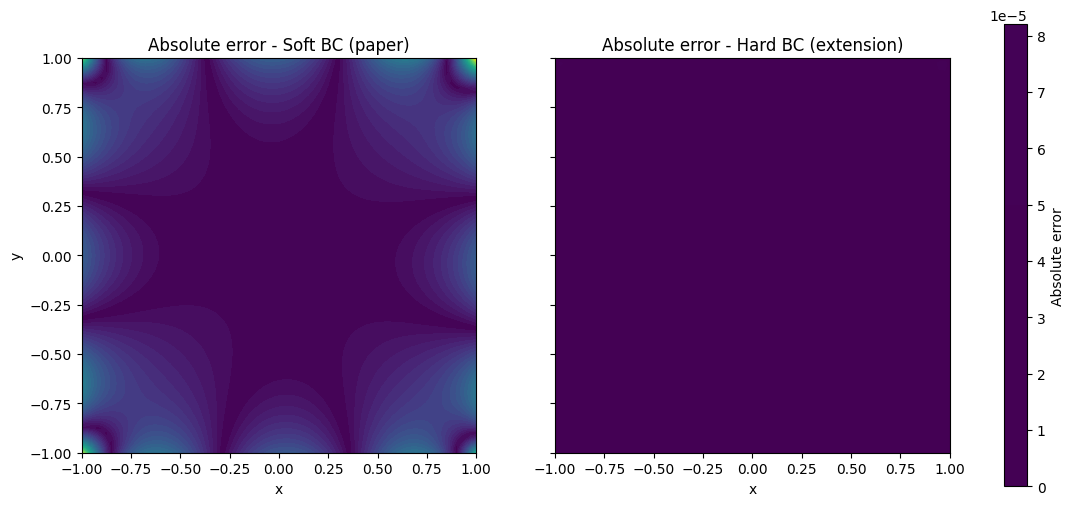

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

vmax = max(T_error_exp2_final.max(), T_error_hard.max())

for ax, err, title in zip(
    axes,
    [T_error_exp2_final, T_error_hard],
    ["Soft BC (paper)", "Hard BC (extension)"]
):
    cs = ax.contourf(X_fd, Y_fd, err, levels=50, cmap="viridis", vmin=0, vmax=vmax)
    ax.set_title(f"Absolute error - {title}")
    ax.set_xlabel("x")
    ax.set_aspect("equal")

axes[0].set_ylabel("y")
fig.colorbar(cs, ax=axes, label="Absolute error")
plt.show()

### Extension Summary

Compare the two models in the table and error maps above. A hard constraint
removes boundary error entirely and leaves the optimizer with a single loss
term (no w_f / w_b trade-off). State in the write-up whichever outcome the
numbers show, including if the improvement is small or absent.

# Part D: Final Comparison

In [ ]:
from IPython.display import Markdown, display

table = f"""
| Experiment | Metric | Ours | Paper |
|---|---|---|---|
| 1. 1D Consolidation | Prediction MSE vs analytical | {prediction_mse:.3e} | not reported |
| 1. 1D Consolidation | Max abs. error | {max_absolute_error:.3e} | not reported |
| 1. 1D Consolidation | Test PDE loss | {test_physics_loss:.3e} | not reported |
| 2. 2D Heat (soft BC) | MSE vs FD reference | {mse_exp2_final:.3e} | not reported |
| 2. 2D Heat (soft BC) | Max abs. error | {max_error_exp2_final:.3e} | not reported |
| 2. 2D Heat (soft BC) | Test PDE loss | {test_pde_loss_exp2:.3e} | not reported |
| 3. Structural Dynamics | c (true 0.4) | {c_final_exp3:.6f} | 0.40125215 |
| 3. Structural Dynamics | k (true 4.0) | {k_final_exp3:.6f} | 3.9933197 |
| 3. Structural Dynamics | Displacement MSE (500 pts) | {prediction_mse_exp3:.3e} | not reported |
| 3. Structural Dynamics | Test displacement MSE (10,000 pts) | {mse_test_exp3:.3e} | not reported |
| 3. Structural Dynamics | Test ODE loss | {ode_test_loss_exp3:.3e} | not reported |
| C. Extension: 2D Heat (hard BC) | MSE vs FD reference | {mse_exp2_hard:.3e} | - |
| C. Extension: 2D Heat (hard BC) | Max abs. error | {max_error_exp2_hard:.3e} | - |
| C. Extension: 2D Heat (hard BC) | Test PDE loss | {test_pde_loss_exp2_hard:.3e} | - |
"""

display(Markdown(table))


| Experiment | Metric | Ours | Paper |
|---|---|---|---|
| 1. 1D Consolidation | Prediction MSE vs analytical | 4.997e-04 | not reported |
| 1. 1D Consolidation | Max abs. error | 3.509e-01 | not reported |
| 1. 1D Consolidation | Test PDE loss | 1.722e+02 | not reported |
| 2. 2D Heat (soft BC) | MSE vs FD reference | 2.659e-06 | not reported |
| 2. 2D Heat (soft BC) | Max abs. error | 1.299e-02 | not reported |
| 2. 2D Heat (soft BC) | Test PDE loss | 1.210e-06 | not reported |
| 3. Structural Dynamics | c (true 0.4) | 0.400816 | 0.40125215 |
| 3. Structural Dynamics | k (true 4.0) | 3.995299 | 3.9933197 |
| 3. Structural Dynamics | Displacement MSE (500 pts) | 1.235e-06 | not reported |
| 3. Structural Dynamics | Test displacement MSE (10,000 pts) | 1.256e-06 | not reported |
| 3. Structural Dynamics | Test ODE loss | 2.191e-04 | not reported |
| C. Extension: 2D Heat (hard BC) | MSE vs FD reference | 4.958e-10 | - |
| C. Extension: 2D Heat (hard BC) | Max abs. error | 8.084e-05 | - |
| C. Extension: 2D Heat (hard BC) | Test PDE loss | 2.267e-04 | - |


## Conclusion

The three experiments from the reference paper were reproduced with
Physics-Informed Neural Networks in PyTorch.

- **Experiment 1 (1D consolidation):** The PINN follows the analytical
  solution on average, but the test PDE residual is far larger than the
  training residual. The error concentrates near x = 0 at small t, where the
  solution has a sharp gradient, consistent with the paper's remark about
  error near the origin.
- **Experiment 2 (2D heat conduction):** The PINN agrees closely with an
  independent finite-difference reference (used in place of the paper's
  deal.II solution). Soft boundary enforcement leaves the largest errors near
  the edges.
- **Experiment 3 (inverse problem):** The PINN recovered c and k to within
  about 0.2% of the true values. The initial guesses for c and k were not
  given in the paper; c = 1, k = 1 did not converge in a 20,000-epoch check,
  and c = 0.5, k = 2.0 (read from the paper's Figure 4) was used for the final run.
- **Extension (hard boundary condition):** Implements the distance-function
  idea proposed in the paper's discussion. See the comparison table for the
  measured effect.

**Limitations:** a single random seed per experiment, a finite-difference
reference instead of finite elements, and several unreported details
(L-BFGS settings, test-point layout, Experiment 3 time range) filled in by
our own choices, each marked in the notebook.